In [ ]:
import pandas as pd
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
sns.set()

In [ ]:
event_df = pd.read_csv("event.csv")
tracking_df = pd.read_csv("tracking.csv")
# ref vid = https://www.youtube.com/watch?v=ut-EcJRm_XA
# time = 3:32

In [ ]:
print("=== Event Data Info ===")
print(event_df.info())
display(event_df.head())

print("\n=== Tracking Data Info ===")
print(tracking_df.info())
display(tracking_df.head())

=== Event Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 481 entries, 0 to 480
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   GAME_ID                    481 non-null    int64  
 1   EVENTNUM                   481 non-null    int64  
 2   EVENTMSGTYPE               481 non-null    int64  
 3   EVENTMSGACTIONTYPE         481 non-null    int64  
 4   PERIOD                     481 non-null    int64  
 5   WCTIMESTRING               481 non-null    object 
 6   PCTIMESTRING               481 non-null    object 
 7   HOMEDESCRIPTION            261 non-null    object 
 8   NEUTRALDESCRIPTION         0 non-null      float64
 9   VISITORDESCRIPTION         235 non-null    object 
 10  SCORE                      108 non-null    object 
 11  SCOREMARGIN                108 non-null    object 
 12  PERSON1TYPE                480 non-null    float64
 13  PLAYER1_ID                

,GAME_ID,EVENTNUM,EVENTMSGTYPE,EVENTMSGACTIONTYPE,PERIOD,WCTIMESTRING,PCTIMESTRING,HOMEDESCRIPTION,NEUTRALDESCRIPTION,VISITORDESCRIPTION,...,PLAYER2_TEAM_CITY,PLAYER2_TEAM_NICKNAME,PLAYER2_TEAM_ABBREVIATION,PERSON3TYPE,PLAYER3_ID,PLAYER3_NAME,PLAYER3_TEAM_ID,PLAYER3_TEAM_CITY,PLAYER3_TEAM_NICKNAME,PLAYER3_TEAM_ABBREVIATION
0,21500436,0,12,0,1,12:07 PM,12:00,NaN,NaN,NaN,...,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN
1,21500436,1,10,0,1,12:07 PM,12:00,Jump Ball Whiteside vs. Davis: Tip to Dragic,NaN,NaN,...,New Orleans,Pelicans,NOP,4,201609,Goran Dragic,1.610613e+09,Miami,Heat,MIA
2,21500436,2,2,1,1,12:07 PM,11:47,MISS Deng 19' Jump Shot,NaN,NaN,...,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN
3,21500436,3,4,0,1,12:07 PM,11:46,NaN,NaN,Davis REBOUND (Off:0 Def:1),...,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN
4,21500436,4,2,80,1,12:08 PM,11:28,NaN,NaN,MISS Davis 16' Step Back Jump Shot,...,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN



=== Tracking Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2594363 entries, 0 to 2594362
Data columns (total 10 columns):
 #   Column      Dtype  
---  ------      -----  
 0   team_id     int64  
 1   player_id   int64  
 2   x_loc       float64
 3   y_loc       float64
 4   radius      float64
 5   game_clock  float64
 6   shot_clock  float64
 7   quarter     int64  
 8   game_id     int64  
 9   event_id    int64  
dtypes: float64(5), int64(5)
memory usage: 197.9 MB
None


,team_id,player_id,x_loc,y_loc,radius,game_clock,shot_clock,quarter,game_id,event_id
0,-1,-1,55.24972,10.16689,3.32578,715.85,16.65,1,21500436,1
1,1610612748,2548,69.41652,5.62885,0.00000,715.85,16.65,1,21500436,1
2,1610612748,2547,65.57599,33.01130,0.00000,715.85,16.65,1,21500436,1
3,1610612748,2736,76.14808,20.76640,0.00000,715.85,16.65,1,21500436,1
4,1610612748,201609,54.62999,9.82980,0.00000,715.85,16.65,1,21500436,1


In [ ]:
# pick a play
plays_to_browse = event_df[
    (event_df['HOMEDESCRIPTION'].notna() | event_df['VISITORDESCRIPTION'].notna())
][['EVENTNUM', 'PERIOD', 'PCTIMESTRING', 'HOMEDESCRIPTION', 'VISITORDESCRIPTION', 'SCORE']].head(30)

display(plays_to_browse)

,EVENTNUM,PERIOD,PCTIMESTRING,HOMEDESCRIPTION,VISITORDESCRIPTION,SCORE
1,1,1,12:00,Jump Ball Whiteside vs. Davis: Tip to Dragic,NaN,NaN
2,2,1,11:47,MISS Deng 19' Jump Shot,NaN,NaN
3,3,1,11:46,NaN,Davis REBOUND (Off:0 Def:1),NaN
4,4,1,11:28,NaN,MISS Davis 16' Step Back Jump Shot,NaN
5,5,1,11:27,Whiteside REBOUND (Off:0 Def:1),NaN,NaN
6,6,1,11:14,Bosh 20' Jump Shot (2 PTS) (Dragic 1 AST),NaN,0 - 2
7,7,1,11:00,NaN,MISS Evans 2' Driving Layup,NaN
8,8,1,10:59,NaN,Davis REBOUND (Off:1 Def:1),NaN
9,10,1,10:40,NaN,MISS Gee 24' 3PT Jump Shot,NaN
10,11,1,10:39,Deng REBOUND (Off:0 Def:1),NaN,NaN


# Choosing an event!


In [ ]:
# 1. Pick an event ID
selected_event_id = 20

# 2. Extract event details
event_info = event_df[event_df['EVENTNUM'] == selected_event_id].copy()
print("--- Selected Event Details ---")
display(event_info[['EVENTNUM', 'PERIOD', 'PCTIMESTRING', 'HOMEDESCRIPTION', 'VISITORDESCRIPTION']])

# 3. Filter tracking data for this specific event
# Note: tracking_df refers to the event ID as 'event_id'
event_tracking = tracking_df[tracking_df['event_id'] == selected_event_id].copy()

print(f"\n--- Loaded {len(event_tracking)} tracking frames for Event {selected_event_id} ---")
display(event_tracking.head())

--- Selected Event Details ---


,EVENTNUM,PERIOD,PCTIMESTRING,HOMEDESCRIPTION,VISITORDESCRIPTION
18,20,1,9:36,Wade Running Dunk (2 PTS) (Dragic 2 AST),NaN



--- Loaded 2222 tracking frames for Event 20 ---


,team_id,player_id,x_loc,y_loc,radius,game_clock,shot_clock,quarter,game_id,event_id
105916,-1,-1,86.35726,24.11849,9.72346,578.99,19.72,1,21500436,20
105917,1610612748,2548,87.27330,22.58520,0.00000,578.99,19.72,1,21500436,20
105918,1610612748,2547,83.06704,40.58914,0.00000,578.99,19.72,1,21500436,20
105919,1610612748,2736,66.65398,43.18840,0.00000,578.99,19.72,1,21500436,20
105920,1610612748,201609,73.11383,14.18814,0.00000,578.99,19.72,1,21500436,20


# Verifying delta time during this event

--- Summary Statistics of Time Steps (seconds) ---
count    201.000000
mean       0.040398
std        0.002615
min        0.030000
25%        0.040000
50%        0.040000
75%        0.040000
max        0.050000
dtype: float64


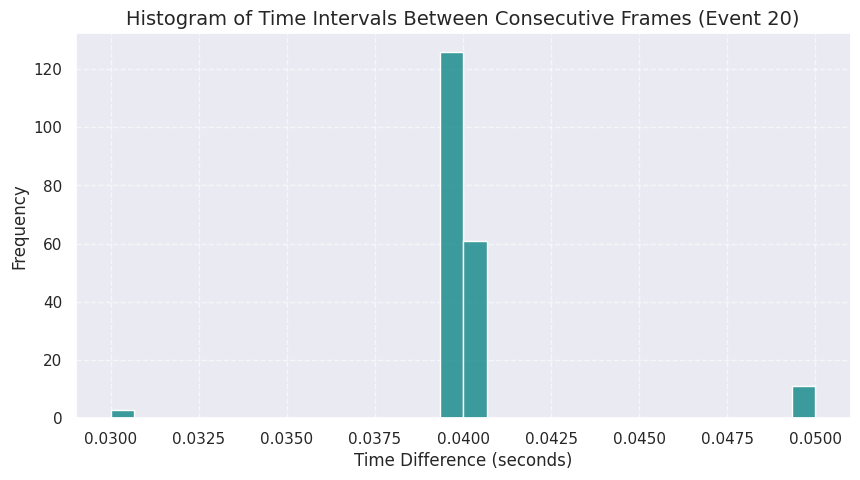

In [ ]:
# 1. Get unique game clock values in descending chronological order
unique_times = pd.Series(sorted(event_tracking['game_clock'].unique(), reverse=True))

# 2. Calculate the difference between consecutive frames
# Since game_clock goes down as time elapses, we take the negative difference to get a positive duration
time_diffs = -unique_times.diff()

# 3. Print basic statistics to inspect the distribution
print("--- Summary Statistics of Time Steps (seconds) ---")
print(time_diffs.describe())

# 4. Plot the histogram of frame-to-frame time differences
plt.figure(figsize=(10, 5))
sns.histplot(time_diffs.dropna(), bins=30, kde=False, color='teal')
plt.title("Histogram of Time Intervals Between Consecutive Frames (Event 20)", fontsize=14)
plt.xlabel("Time Difference (seconds)")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Basic info about Event

In [ ]:
# 1. Count of frames (unique game_clock timestamps)
num_frames = event_tracking['game_clock'].nunique()

# 2. Count of unique players + ball (-1)
unique_entities = event_tracking['player_id'].nunique()
unique_players = event_tracking[event_tracking['player_id'] != -1]['player_id'].nunique()

# 3. Calculate event duration (seconds)
start_time = event_tracking['game_clock'].max()
end_time = event_tracking['game_clock'].min()
duration_seconds = start_time - end_time

# Convert to minutes and seconds
duration_minutes = int(duration_seconds // 60)
remaining_seconds = duration_seconds % 60

# Display the results clearly
print("=== Event 20 Basic Tracking Stats ===")
print(f"Total unique frames: {num_frames}")
print(f"Total unique players: {unique_players} (plus the ball)")
print(f"Event duration: {duration_seconds:.2f} seconds ({duration_minutes}m {remaining_seconds:.2f}s)")

=== Event 20 Basic Tracking Stats ===
Total unique frames: 202
Total unique players: 10 (plus the ball)
Event duration: 8.12 seconds (0m 8.12s)


In [ ]:
# Finding the bounds of the data
x_min, x_max = event_tracking['x_loc'].min(), event_tracking['x_loc'].max()
y_min, y_max = event_tracking['y_loc'].min(), event_tracking['y_loc'].max()

print(f"X-axis bounds: ({x_min}, {x_max})")
print(f"Y-axis bounds: ({y_min}, {y_max})")

# Final ball location
ball_x, ball_y = event_tracking[event_tracking['player_id'] == -1][['x_loc', 'y_loc']].values[0]
print(f"Final ball location: ({ball_x}, {ball_y})")

X-axis bounds: (7.8667, 94.98681)
Y-axis bounds: (0.62621, 50.65352)
Final ball location: (86.35726, 24.11849)


### Plotting Player Trajectories
We will group our `event_tracking` DataFrame by `player_id` to draw each player's movement path.

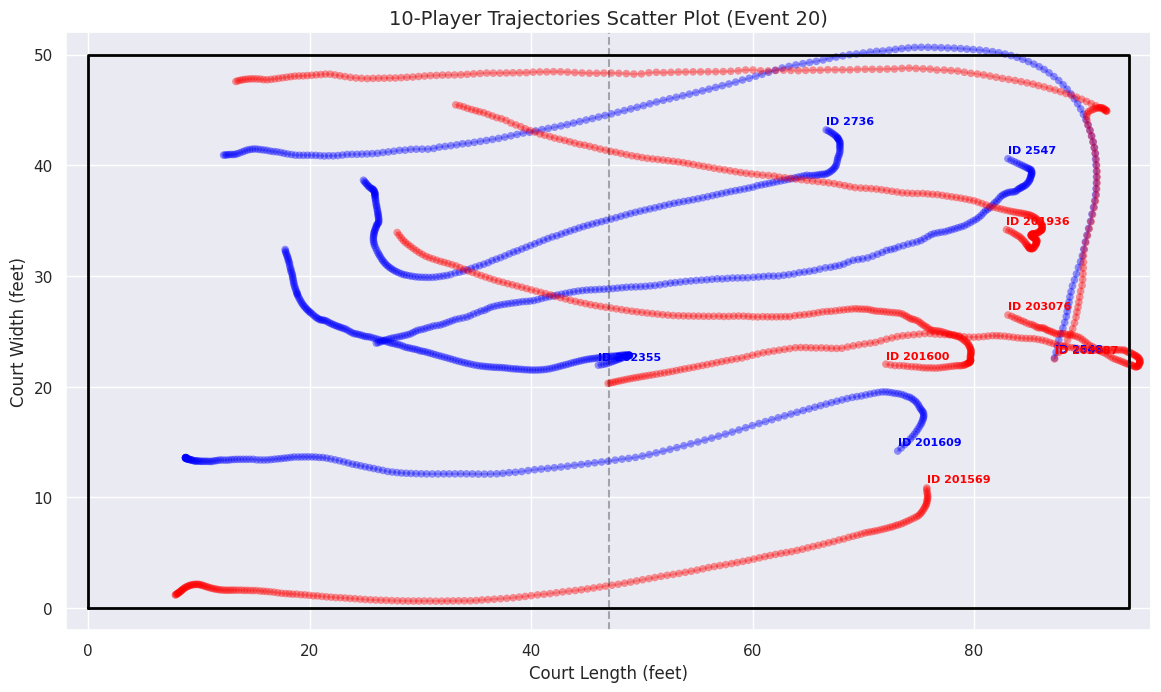

In [ ]:
plt.figure(figsize=(14, 8))

# Extract unique team IDs (excluding -1 which represents the ball)
team_ids = [tid for tid in event_tracking['team_id'].unique() if tid != -1]

# 1. Plot the court outline
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='black', lw=2)
plt.axvline(x=47, color='black', linestyle='--', alpha=0.3)  # Midcourt

# 2. Extract players data only (excluding the ball)
players_tracking = event_tracking[event_tracking['player_id'] != -1]

# Get team colors
# We will color team 1 in Blue/Cyan and team 2 in Red/Orange
home_team_id = team_ids[0]

# 3. Loop over each unique player and plot their trajectory
for player_id in players_tracking['player_id'].unique():
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)

    # Determine color based on team
    team_id = player_data['team_id'].iloc[0]
    color = 'blue' if team_id == home_team_id else 'red'

    # Scatter plot of all positions occupied by this player during the event
    plt.scatter(
        player_data['x_loc'],
        player_data['y_loc'],
        color=color,
        alpha=0.4,
        s=30,
        edgecolors='none'
    )

    # Draw a light line connecting the steps to visualize direction
    plt.plot(
        player_data['x_loc'],
        player_data['y_loc'],
        color=color,
        alpha=0.2
    )

    # Label the starting position of each player
    start_pos = player_data.iloc[0]
    plt.text(
        start_pos['x_loc'],
        start_pos['y_loc'] + 0.5,
        f"ID {int(player_id)}",
        fontsize=8,
        weight='bold',
        color=color
    )

plt.title("10-Player Trajectories Scatter Plot (Event 20)", fontsize=14)
plt.xlim(-2, 96)
plt.ylim(-2, 52)
plt.xlabel("Court Length (feet)")
plt.ylabel("Court Width (feet)")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()

### Player Trajectories with an Inverted Y-Axis
By adding `plt.gca().invert_yaxis()`, we flip the court upside down. This is useful if the tracking coordinates treat the top-left of the court as the origin.

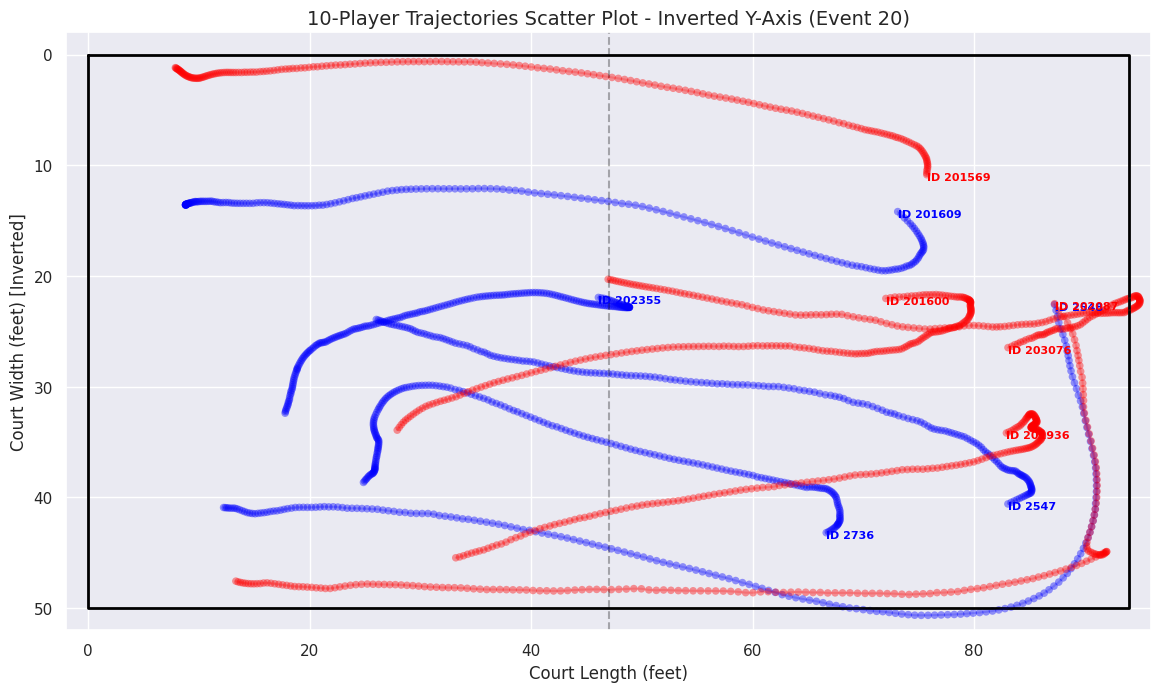

In [ ]:
plt.figure(figsize=(14, 8))

# 1. Plot the court outline
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='black', lw=2)
plt.axvline(x=47, color='black', linestyle='--', alpha=0.3)

# 2. Extract players tracking data
players_tracking = event_tracking[event_tracking['player_id'] != -1]
home_team_id = team_ids[0]

# 3. Loop and plot each player's trajectory
for player_id in players_tracking['player_id'].unique():
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)

    team_id = player_data['team_id'].iloc[0]
    color = 'blue' if team_id == home_team_id else 'red'

    # Scatter points
    plt.scatter(
        player_data['x_loc'],
        player_data['y_loc'],
        color=color,
        alpha=0.4,
        s=30,
        edgecolors='none'
    )

    # Connect points with a light line
    plt.plot(
        player_data['x_loc'],
        player_data['y_loc'],
        color=color,
        alpha=0.2
    )

    # Label the starting position of each player
    start_pos = player_data.iloc[0]
    plt.text(
        start_pos['x_loc'],
        start_pos['y_loc'] + 0.5,
        f"ID {int(player_id)}",
        fontsize=8,
        weight='bold',
        color=color
    )

# 4. Invert the Y-axis to reverse court orientation
plt.gca().invert_yaxis()

plt.title("10-Player Trajectories Scatter Plot - Inverted Y-Axis (Event 20)", fontsize=14)
plt.xlim(-2, 96)
plt.ylim(52, -2) # Adjusted limits to accommodate the inversion
plt.xlabel("Court Length (feet)")
plt.ylabel("Court Width (feet) [Inverted]")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

### Plotting the Ball Trajectory Alongside Players
We'll filter the data for `player_id == -1` to obtain the ball's coordinates, and plot them alongside the players' trajectories.

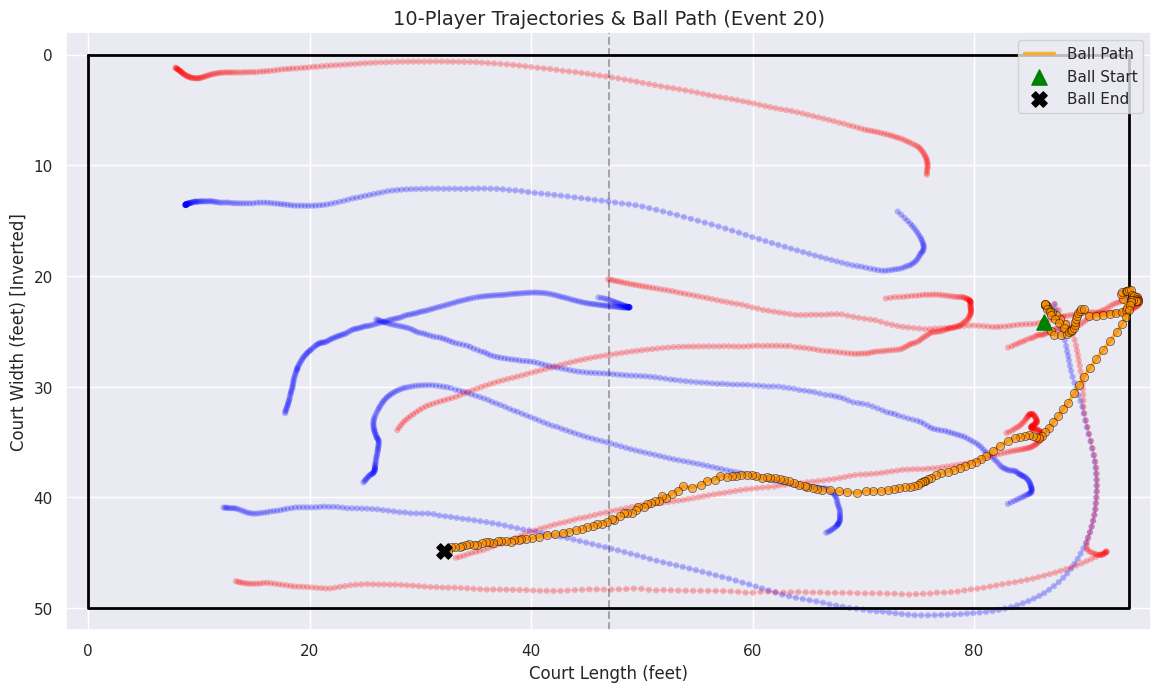

In [ ]:
plt.figure(figsize=(14, 8))

# 1. Plot the court outline
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='black', lw=2)
plt.axvline(x=47, color='black', linestyle='--', alpha=0.3)

# 2. Extract players tracking data & team info
players_tracking = event_tracking[event_tracking['player_id'] != -1]
home_team_id = team_ids[0]

# 3. Plot player trajectories
for player_id in players_tracking['player_id'].unique():
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)

    team_id = player_data['team_id'].iloc[0]
    color = 'blue' if team_id == home_team_id else 'red'

    # Scatter player steps with low alpha
    plt.scatter(
        player_data['x_loc'],
        player_data['y_loc'],
        color=color,
        alpha=0.25,
        s=20,
        edgecolors='none'
    )
    plt.plot(
        player_data['x_loc'],
        player_data['y_loc'],
        color=color,
        alpha=0.1
    )

# 4. Extract and Plot the Ball Trajectory
ball_tracking = event_tracking[event_tracking['player_id'] == -1].sort_values('game_clock', ascending=False)

# Plot the ball trajectory with high visibility (orange color, slightly larger dots)
plt.plot(
    ball_tracking['x_loc'],
    ball_tracking['y_loc'],
    color='orange',
    linewidth=2.5,
    alpha=0.8,
    label='Ball Path'
)
plt.scatter(
    ball_tracking['x_loc'],
    ball_tracking['y_loc'],
    color='darkorange',
    s=35,
    alpha=0.6,
    edgecolors='black',
    lw=0.5,
    zorder=5
)

# Mark the start and end of the ball's path to see where the play went
if len(ball_tracking) > 0:
    ball_start = ball_tracking.iloc[0]
    ball_end = ball_tracking.iloc[-1]
    plt.scatter(ball_start['x_loc'], ball_start['y_loc'], color='green', marker='^', s=120, zorder=6, label='Ball Start')
    plt.scatter(ball_end['x_loc'], ball_end['y_loc'], color='black', marker='X', s=120, zorder=6, label='Ball End')

plt.gca().invert_yaxis()

plt.title("10-Player Trajectories & Ball Path (Event 20)", fontsize=14)
plt.xlim(-2, 96)
plt.ylim(52, -2)
plt.xlabel("Court Length (feet)")
plt.ylabel("Court Width (feet) [Inverted]")
plt.legend(loc='upper right')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

### Step 1: Examine the Official Play-by-Play Description
Let's pull all non-null columns from the event log for Event 20 to read exactly how the scorers recorded this play.

In [ ]:
# Retrieve and display the event description
event_row = event_df[event_df['EVENTNUM'] == 20].dropna(axis=1)
display(event_row)

,GAME_ID,EVENTNUM,EVENTMSGTYPE,EVENTMSGACTIONTYPE,PERIOD,WCTIMESTRING,PCTIMESTRING,HOMEDESCRIPTION,SCORE,SCOREMARGIN,...,PLAYER1_TEAM_ABBREVIATION,PERSON2TYPE,PLAYER2_ID,PLAYER2_NAME,PLAYER2_TEAM_ID,PLAYER2_TEAM_CITY,PLAYER2_TEAM_NICKNAME,PLAYER2_TEAM_ABBREVIATION,PERSON3TYPE,PLAYER3_ID
18,21500436,20,1,50,1,12:10 PM,9:36,Wade Running Dunk (2 PTS) (Dragic 2 AST),0 - 7,7,...,MIA,4,201609,Goran Dragic,1.610613e+09,Miami,Heat,MIA,0,0


### Step 2: Correlating the Visualization with the Description
Now we can examine the coordinates to map the physical actions to the text description.
* Let's plot the ball trajectory again, but this time we'll label several timestamps chronologically along the path.
* This helps us see which player IDs were closest to the ball at the start, middle, and end of the play.

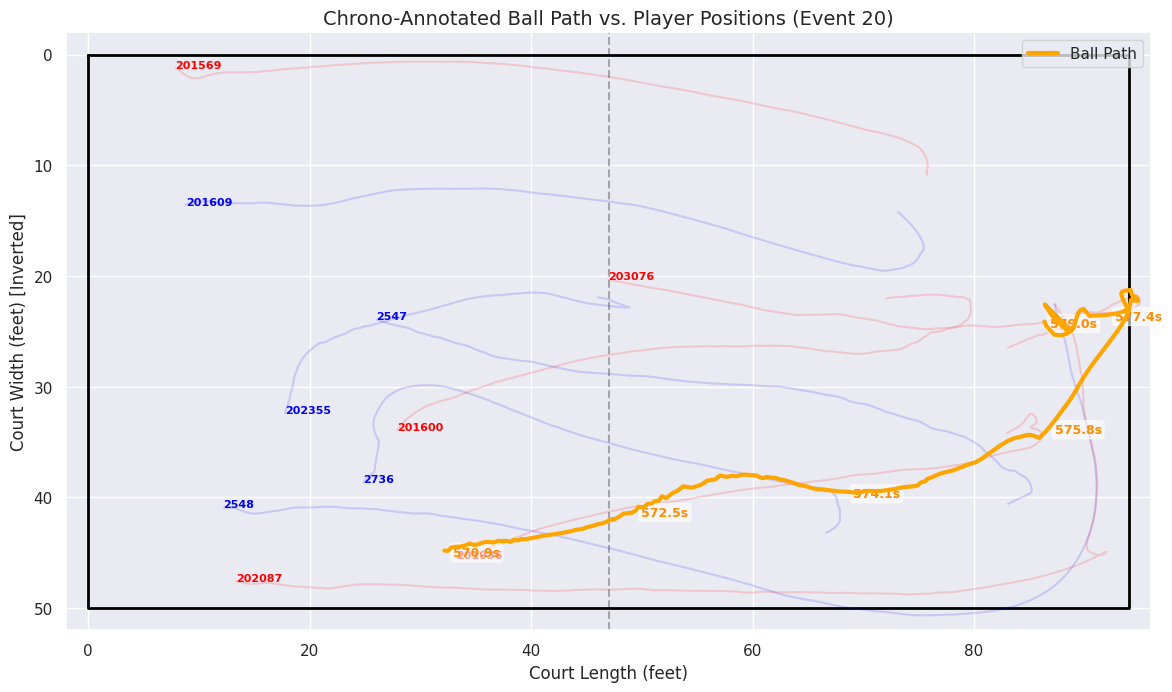

In [ ]:
plt.figure(figsize=(14, 8))

# 1. Plot standard court outline
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='black', lw=2)
plt.axvline(x=47, color='black', linestyle='--', alpha=0.3)

# 2. Plot player trajectories with high transparency to keep the focus on the ball
players_tracking = event_tracking[event_tracking['player_id'] != -1]
home_team_id = team_ids[0]

for player_id in players_tracking['player_id'].unique():
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)
    team_id = player_data['team_id'].iloc[0]
    color = 'blue' if team_id == home_team_id else 'red'

    plt.plot(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.15, lw=1.5)

    # Mark where players ended up at the end of the play
    end_pos = player_data.iloc[-1]
    plt.text(end_pos['x_loc'], end_pos['y_loc'], f"{int(player_id)}", color=color, fontsize=8, weight='bold')

# 3. Plot the ball trajectory
ball_tracking = event_tracking[event_tracking['player_id'] == -1].sort_values('game_clock', ascending=False)
plt.plot(ball_tracking['x_loc'], ball_tracking['y_loc'], color='orange', linewidth=3, label='Ball Path', zorder=4)

# 4. Add time markers on the ball trajectory to see the direction of the play
# We will place a text label every 40 frames (~1.6 seconds)
for i in range(0, len(ball_tracking), 40):
    row = ball_tracking.iloc[i]
    plt.text(row['x_loc'] + 0.5, row['y_loc'] + 0.5, f"{row['game_clock']:.1f}s",
             color='darkorange', fontsize=9, weight='bold', bbox=dict(facecolor='white', alpha=0.6, boxstyle='round,pad=0.2'))

plt.gca().invert_yaxis()
plt.title("Chrono-Annotated Ball Path vs. Player Positions (Event 20)", fontsize=14)
plt.xlim(-2, 96)
plt.ylim(52, -2)
plt.xlabel("Court Length (feet)")
plt.ylabel("Court Width (feet) [Inverted]")
plt.legend(loc='upper right')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

### Step 1: Build the Player Name Dictionary
We will extract all combinations of player IDs and names from the dataset and construct a dictionary for easy lookups.

In [ ]:
# 1. Build a dictionary mapping player_id to player_name from all event records
player_map = {}

# We check all three possible player columns in the event dataset
for p_id_col, p_name_col in [
    ('PLAYER1_ID', 'PLAYER1_NAME'),
    ('PLAYER2_ID', 'PLAYER2_NAME'),
    ('PLAYER3_ID', 'PLAYER3_NAME')
]:
    # Drop rows where ID or Name is null/0
    valid_players = event_df[event_df[p_id_col].notna() & event_df[p_name_col].notna()]
    for _, row in valid_players.iterrows():
        pid = int(row[p_id_col])
        pname = row[p_name_col]
        if pid != 0 and pname != "":
            player_map[pid] = pname

# 2. Identify the active players in Event 20 and show their names
active_pids = [pid for pid in event_tracking['player_id'].unique() if pid != -1]
print("=== Active Roster for Event 20 ===")
for pid in active_pids:
    name = player_map.get(pid, f"Unknown Player ({pid})")
    print(f"ID: {pid} -> Name: {name}")

=== Active Roster for Event 20 ===
ID: 2548 -> Name: Dwyane Wade
ID: 2547 -> Name: Chris Bosh
ID: 2736 -> Name: Luol Deng
ID: 201609 -> Name: Goran Dragic
ID: 202355 -> Name: Hassan Whiteside
ID: 202087 -> Name: Alonzo Gee
ID: 201569 -> Name: Eric Gordon
ID: 201600 -> Name: Omer Asik
ID: 201936 -> Name: Tyreke Evans
ID: 203076 -> Name: Anthony Davis


### Step 2: Plot Trajectories with Player Names
Now, we'll plot the player paths and label them with their real names using the dictionary we built.

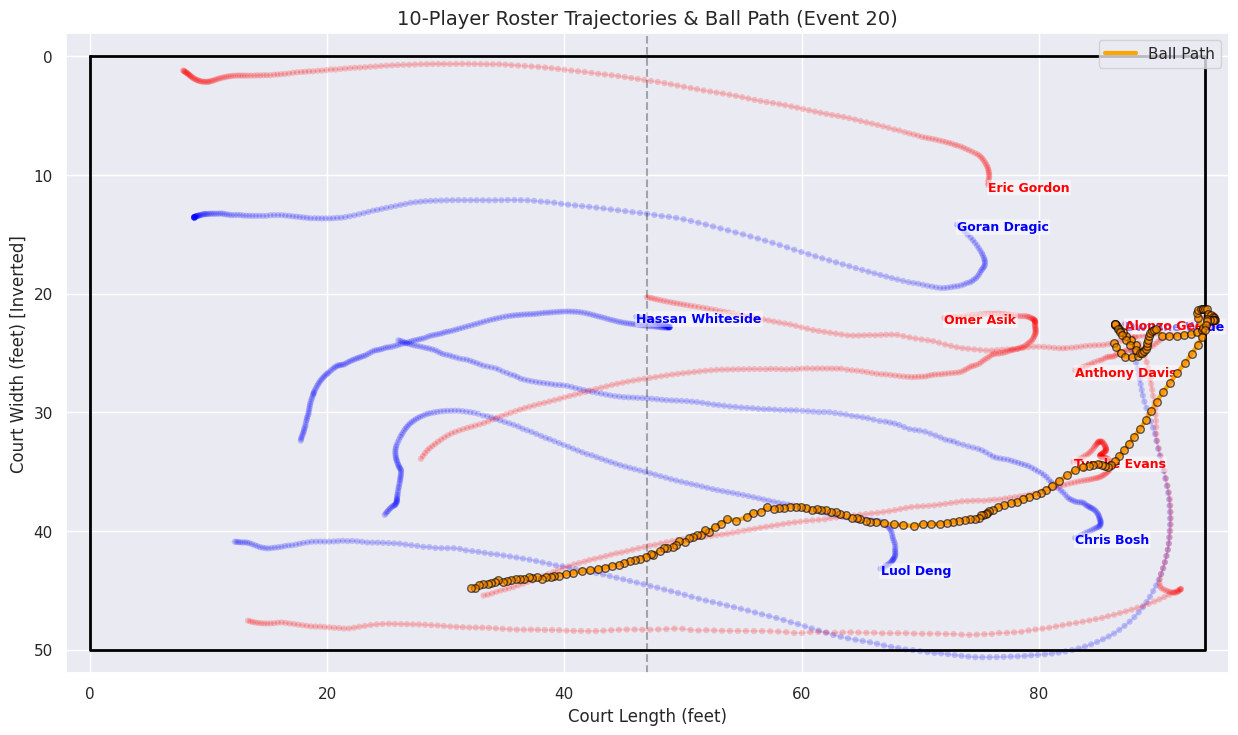

In [ ]:
plt.figure(figsize=(15, 9))

# 1. Plot Court
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='black', lw=2)
plt.axvline(x=47, color='black', linestyle='--', alpha=0.3)

# 2. Plot players with names
players_tracking = event_tracking[event_tracking['player_id'] != -1]
home_team_id = team_ids[0]

for player_id in players_tracking['player_id'].unique():
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)
    team_id = player_data['team_id'].iloc[0]
    color = 'blue' if team_id == home_team_id else 'red'

    # Scatter paths
    plt.scatter(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.2, s=20, edgecolors='none')
    plt.plot(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.1)

    # Label with Name instead of ID
    player_name = player_map.get(int(player_id), f"ID {int(player_id)}")
    start_pos = player_data.iloc[0]
    plt.text(
        start_pos['x_loc'],
        start_pos['y_loc'] + 0.5,
        player_name,
        fontsize=9,
        weight='bold',
        color=color,
        bbox=dict(facecolor='white', alpha=0.5, boxstyle='round,pad=0.1', edgecolor='none')
    )

# 3. Plot Ball Trajectory
ball_tracking = event_tracking[event_tracking['player_id'] == -1].sort_values('game_clock', ascending=False)
plt.plot(ball_tracking['x_loc'], ball_tracking['y_loc'], color='orange', linewidth=3, label='Ball Path', zorder=4)
plt.scatter(ball_tracking['x_loc'], ball_tracking['y_loc'], color='darkorange', s=30, alpha=0.6, edgecolors='black', zorder=5)

plt.gca().invert_yaxis()
plt.title("10-Player Roster Trajectories & Ball Path (Event 20)", fontsize=14)
plt.xlim(-2, 96)
plt.ylim(52, -2)
plt.xlabel("Court Length (feet)")
plt.ylabel("Court Width (feet) [Inverted]")
plt.legend(loc='upper right')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

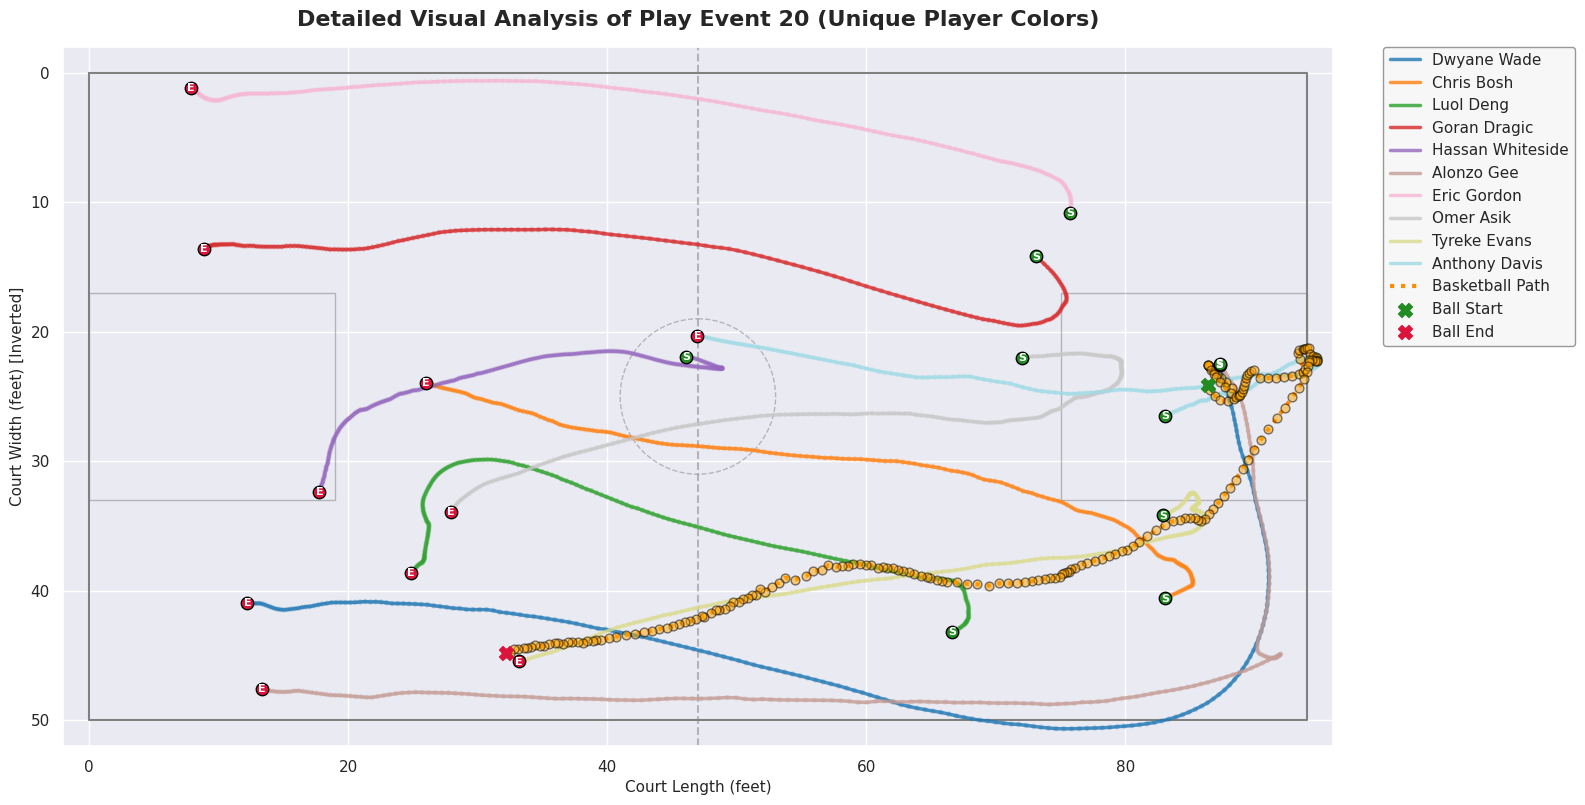

PLAY DESCRIPTION: Wade  Running Dunk (2 PTS) (Dragic 2 AST)


In [ ]:
import matplotlib.patches as patches
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10))
ax = plt.gca()

# 1. Draw a basketball court layout
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='gray', lw=1.5)
plt.axvline(x=47, color='gray', linestyle='--', alpha=0.5) # Midcourt line

# Center circle
center_circle = patches.Circle((47, 25), 6, edgecolor='gray', facecolor='none', alpha=0.5, linestyle='--')
ax.add_patch(center_circle)

# Left and Right Key/Paint
left_paint = patches.Rectangle((0, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5)
right_paint = patches.Rectangle((75, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5)
ax.add_patch(left_paint)
ax.add_patch(right_paint)

# 2. Extract unique players and assign each a completely distinct, unique color
unique_pids = players_tracking['player_id'].unique()
colors_pool = plt.cm.tab20(np.linspace(0, 1, len(unique_pids)))
player_colors = {pid: colors_pool[idx] for idx, pid in enumerate(unique_pids)}

# 3. Plot player paths and flag their Start (S) & End (E) points
for player_id in unique_pids:
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)

    color = player_colors[player_id]
    player_name = player_map.get(int(player_id), f"ID {int(player_id)}")

    # Plot trajectory line
    plt.plot(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.8, lw=2.5, label=player_name)
    # Scatter subtle dots along the path
    plt.scatter(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.3, s=15, edgecolors='none')

    # Identify and plot Start (S) and End (E)
    start_pos = player_data.iloc[0]
    end_pos = player_data.iloc[-1]

    # Start Marker 'S' - explicitly hardcoded text 'S' to avoid any index issues
    plt.scatter(start_pos['x_loc'], start_pos['y_loc'], color='forestgreen', edgecolors='black', s=80, zorder=6)
    plt.text(start_pos['x_loc'], start_pos['y_loc'], 'S', color='white', fontsize=8, weight='bold', ha='center', va='center', zorder=7)

    # End Marker 'E' - explicitly hardcoded text 'E' to avoid any index issues
    plt.scatter(end_pos['x_loc'], end_pos['y_loc'], color='crimson', edgecolors='black', s=80, zorder=6)
    plt.text(end_pos['x_loc'], end_pos['y_loc'], 'E', color='white', fontsize=8, weight='bold', ha='center', va='center', zorder=7)

# 4. Plot the ball's trajectory
ball_tracking = event_tracking[event_tracking['player_id'] == -1].sort_values('game_clock', ascending=False)
plt.plot(ball_tracking['x_loc'], ball_tracking['y_loc'], color='darkorange', linewidth=3, linestyle=':', label='Basketball Path', zorder=4)
plt.scatter(ball_tracking['x_loc'], ball_tracking['y_loc'], color='orange', s=40, alpha=0.5, edgecolors='black', zorder=5)

# Ball Start & End
if len(ball_tracking) > 0:
    b_start = ball_tracking.iloc[0]
    b_end = ball_tracking.iloc[-1]
    plt.scatter(b_start['x_loc'], b_start['y_loc'], color='forestgreen', marker='X', s=100, label='Ball Start', zorder=8)
    plt.scatter(b_end['x_loc'], b_end['y_loc'], color='crimson', marker='X', s=100, label='Ball End', zorder=8)

# 5. Invert court layout as requested
plt.gca().invert_yaxis()

# 6. Aesthetic Formatting
plt.title("Detailed Visual Analysis of Play Event 20 (Unique Player Colors)", fontsize=16, weight='bold', pad=15)
plt.xlim(-2, 96)
plt.ylim(52, -2)
plt.xlabel("Court Length (feet)", fontsize=11)
plt.ylabel("Court Width (feet) [Inverted]", fontsize=11)

# Put the legend outside on the right side
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, frameon=True, facecolor='whitesmoke', edgecolor='gray')
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

# Retrieve description for the caption
event_row = event_df[event_df['EVENTNUM'] == 20].iloc[0]
home_desc = event_row.get('HOMEDESCRIPTION', '')
visit_desc = event_row.get('VISITORDESCRIPTION', '')
play_description = home_desc if pd.notna(home_desc) else (visit_desc if pd.notna(visit_desc) else 'No description available.')

print("="*80)
print(f"PLAY DESCRIPTION: {play_description}")
print("="*80)

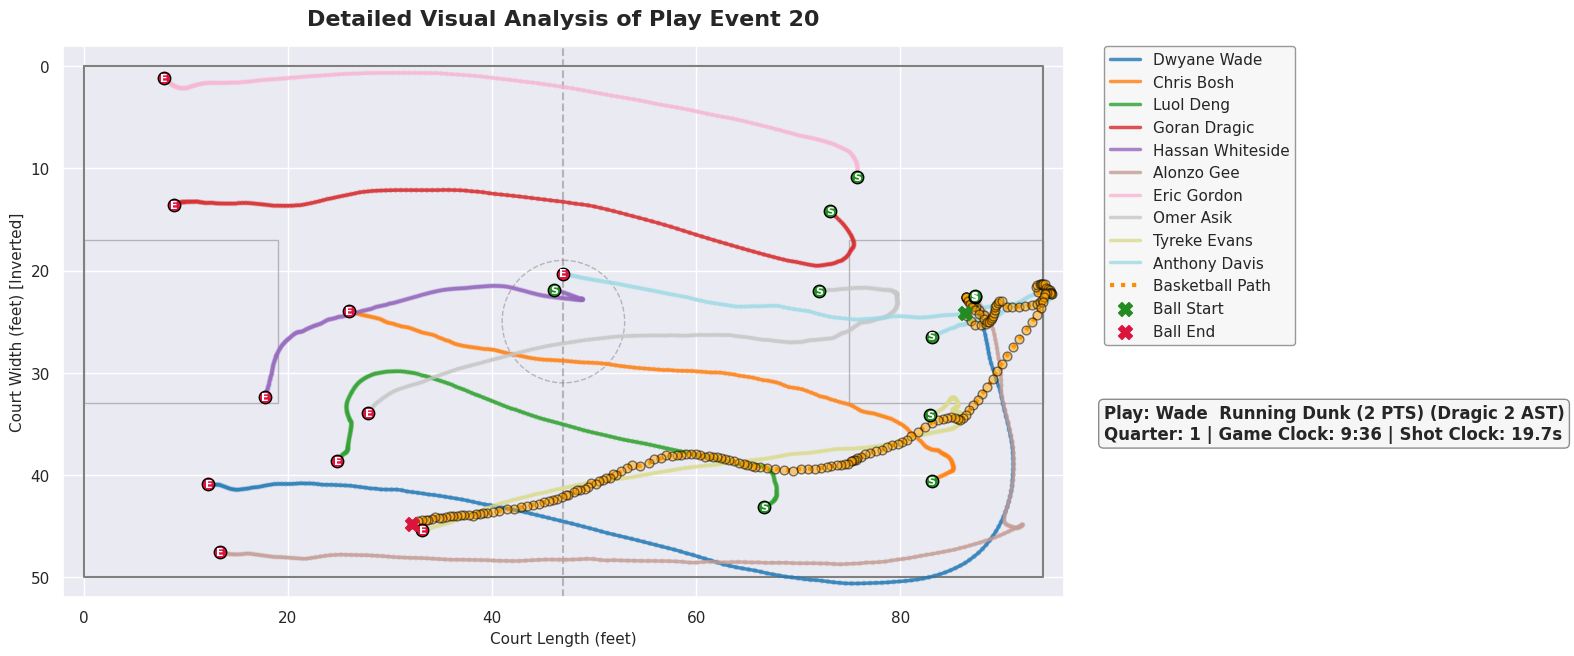

In [ ]:
import matplotlib.patches as patches
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(16, 11))
ax = plt.gca()

# 1. Draw a basketball court layout
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='gray', lw=1.5)
plt.axvline(x=47, color='gray', linestyle='--', alpha=0.5) # Midcourt line

# Center circle
center_circle = patches.Circle((47, 25), 6, edgecolor='gray', facecolor='none', alpha=0.5, linestyle='--')
ax.add_patch(center_circle)

# Left and Right Key/Paint
left_paint = patches.Rectangle((0, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5)
right_paint = patches.Rectangle((75, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5)
ax.add_patch(left_paint)
ax.add_patch(right_paint)

# 2. Extract unique players and assign each a completely distinct, unique color
unique_pids = players_tracking['player_id'].unique()
colors_pool = plt.cm.tab20(np.linspace(0, 1, len(unique_pids)))
player_colors = {pid: colors_pool[idx] for idx, pid in enumerate(unique_pids)}

# 3. Plot player paths and flag their Start (S) & End (E) points
for player_id in unique_pids:
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)

    color = player_colors[player_id]
    player_name = player_map.get(int(player_id), f"ID {int(player_id)}")

    # Plot trajectory line
    plt.plot(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.8, lw=2.5, label=player_name)
    # Scatter subtle dots along the path
    plt.scatter(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.3, s=15, edgecolors='none')

    # Identify and plot Start (S) and End (E)
    start_pos = player_data.iloc[0]
    end_pos = player_data.iloc[-1]

    # Start Marker 'S'
    plt.scatter(start_pos['x_loc'], start_pos['y_loc'], color='forestgreen', edgecolors='black', s=80, zorder=6)
    plt.text(start_pos['x_loc'], start_pos['y_loc'], 'S', color='white', fontsize=8, weight='bold', ha='center', va='center', zorder=7)

    # End Marker 'E'
    plt.scatter(end_pos['x_loc'], end_pos['y_loc'], color='crimson', edgecolors='black', s=80, zorder=6)
    plt.text(end_pos['x_loc'], end_pos['y_loc'], 'E', color='white', fontsize=8, weight='bold', ha='center', va='center', zorder=7)

# 4. Plot the ball's trajectory
ball_tracking = event_tracking[event_tracking['player_id'] == -1].sort_values('game_clock', ascending=False)
plt.plot(ball_tracking['x_loc'], ball_tracking['y_loc'], color='darkorange', linewidth=3, linestyle=':', label='Basketball Path', zorder=4)
plt.scatter(ball_tracking['x_loc'], ball_tracking['y_loc'], color='orange', s=40, alpha=0.5, edgecolors='black', zorder=5)

# Ball Start & End
if len(ball_tracking) > 0:
    b_start = ball_tracking.iloc[0]
    b_end = ball_tracking.iloc[-1]
    plt.scatter(b_start['x_loc'], b_start['y_loc'], color='forestgreen', marker='X', s=100, label='Ball Start', zorder=8)
    plt.scatter(b_end['x_loc'], b_end['y_loc'], color='crimson', marker='X', s=100, label='Ball End', zorder=8)

# 5. Invert court layout
plt.gca().invert_yaxis()

# 6. Extract dynamic event details for the visual caption
event_row = event_df[event_df['EVENTNUM'] == 20].iloc[0]
home_desc = event_row.get('HOMEDESCRIPTION', '')
visit_desc = event_row.get('VISITORDESCRIPTION', '')
play_description = home_desc if pd.notna(home_desc) else (visit_desc if pd.notna(visit_desc) else 'No description available.')

quarter = int(event_row.get('PERIOD', 1))
game_clock_str = str(event_row.get('PCTIMESTRING', '00:00'))
# Fetch shot clock if available from the tracking data
shot_clocks = event_tracking['shot_clock'].dropna()
shot_clock_val = f"{shot_clocks.iloc[0]:.1f}s" if len(shot_clocks) > 0 else "N/A"

caption_text = (
    f"Play: {play_description}\n"
    f"Quarter: {quarter} | Game Clock: {game_clock_str} | Shot Clock: {shot_clock_val}"
)

# 7. Add Caption OUTSIDE the graph (directly under the legend box on the right)
props = dict(boxstyle='round', facecolor='whitesmoke', alpha=0.9, edgecolor='gray')
# TransAxes coordinates at (1.04, 0.35) place it cleanly on the side panel
ax.text(1.04, 0.35, caption_text, transform=ax.transAxes, fontsize=12, weight='bold',
        verticalalignment='top', bbox=props, zorder=10)

# Aesthetic Formatting
plt.title("Detailed Visual Analysis of Play Event 20", fontsize=16, weight='bold', pad=15)
plt.xlim(-2, 96)
plt.ylim(52, -2)
plt.xlabel("Court Length (feet)", fontsize=11)
plt.ylabel("Court Width (feet) [Inverted]", fontsize=11)

# Put the legend outside on the right side
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, frameon=True, facecolor='whitesmoke', edgecolor='gray')
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

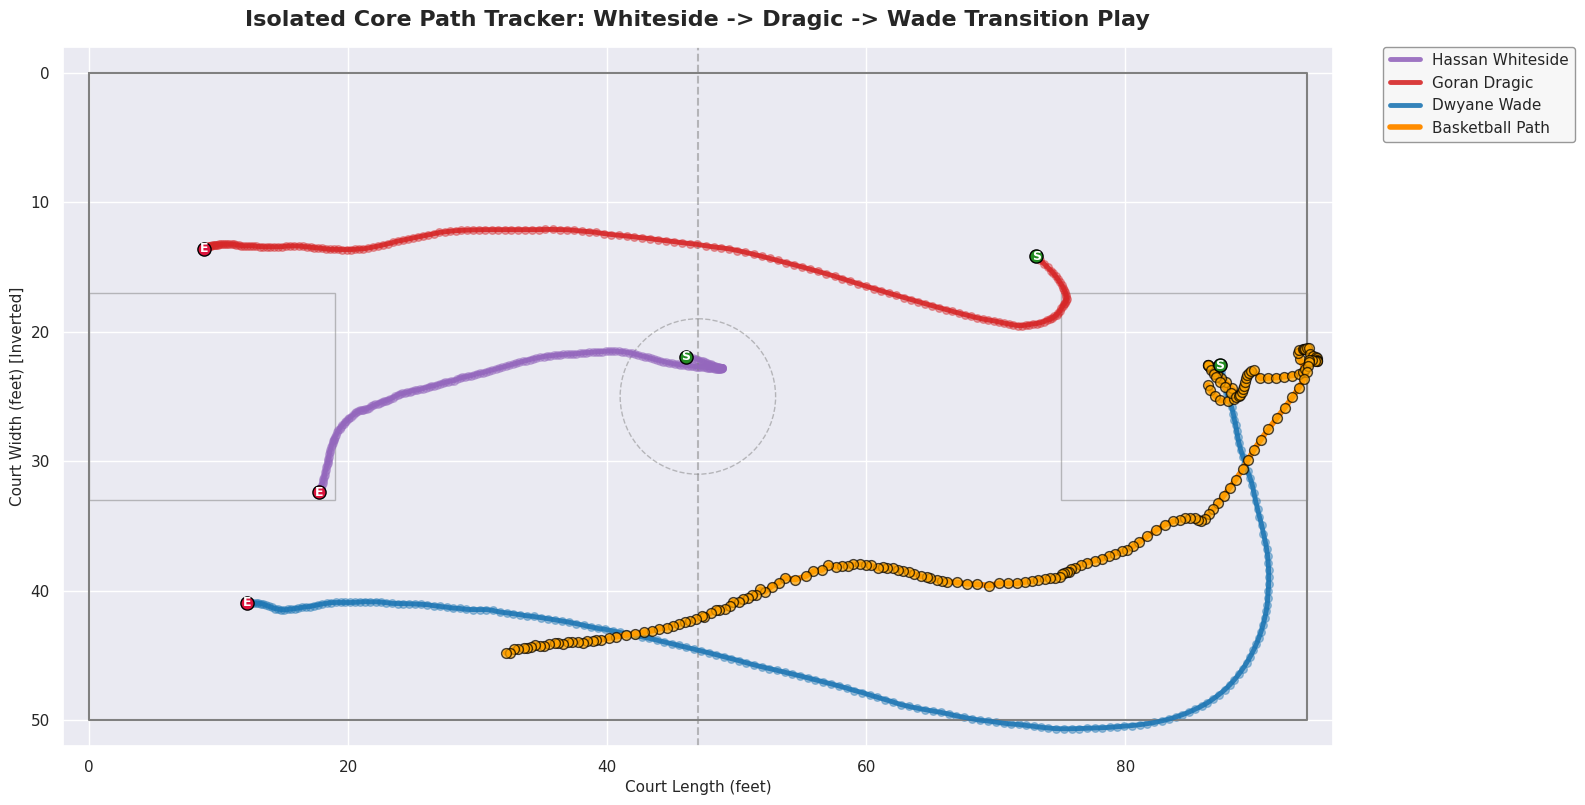

In [ ]:
import matplotlib.patches as patches
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# IDs for our core playmakers
whiteside_id = 202355
dragic_id = 201609
wade_id = 2548
core_ids = [whiteside_id, dragic_id, wade_id]

# Filter tracking data
players_tracking = event_tracking[event_tracking['player_id'] != -1]
ball_tracking = event_tracking[event_tracking['player_id'] == -1].sort_values('game_clock', ascending=False)

# -----------------------------------------------------
# GRAPH 1: Isolated Trio (Whiteside, Dragic, Wade) + Ball
# -----------------------------------------------------
plt.figure(figsize=(16, 11))
ax = plt.gca()

# Draw basketball court layout
plt.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='gray', lw=1.5)
plt.axvline(x=47, color='gray', linestyle='--', alpha=0.5)
ax.add_patch(patches.Circle((47, 25), 6, edgecolor='gray', facecolor='none', alpha=0.5, linestyle='--'))
ax.add_patch(patches.Rectangle((0, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
ax.add_patch(patches.Rectangle((75, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))

# Plot only core players
for player_id in core_ids:
    player_data = players_tracking[players_tracking['player_id'] == player_id].sort_values('game_clock', ascending=False)
    color = player_colors[player_id]
    player_name = player_map.get(int(player_id), f"ID {int(player_id)}")

    plt.plot(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.9, lw=3.5, label=player_name)
    plt.scatter(player_data['x_loc'], player_data['y_loc'], color=color, alpha=0.4, s=30)

    # Mark Start & End for each profile
    start_pos = player_data.iloc[0]
    end_pos = player_data.iloc[-1]

    plt.scatter(start_pos['x_loc'], start_pos['y_loc'], color='forestgreen', edgecolors='black', s=90, zorder=6)
    plt.text(start_pos['x_loc'], start_pos['y_loc'], 'S', color='white', fontsize=9, weight='bold', ha='center', va='center', zorder=7)

    plt.scatter(end_pos['x_loc'], end_pos['y_loc'], color='crimson', edgecolors='black', s=90, zorder=6)
    plt.text(end_pos['x_loc'], end_pos['y_loc'], 'E', color='white', fontsize=9, weight='bold', ha='center', va='center', zorder=7)

# Plot the ball trajectory
plt.plot(ball_tracking['x_loc'], ball_tracking['y_loc'], color='darkorange', linewidth=4, linestyle='-', label='Basketball Path', zorder=4)
plt.scatter(ball_tracking['x_loc'], ball_tracking['y_loc'], color='orange', s=50, alpha=0.7, edgecolors='black', zorder=5)

plt.gca().invert_yaxis()
plt.title("Isolated Core Path Tracker: Whiteside -> Dragic -> Wade Transition Play", fontsize=16, weight='bold', pad=15)
plt.xlim(-2, 96)
plt.ylim(52, -2)
plt.xlabel("Court Length (feet)", fontsize=11)
plt.ylabel("Court Width (feet) [Inverted]", fontsize=11)
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0, frameon=True, facecolor='whitesmoke', edgecolor='gray')
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.patches as patches
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# 1. Setup figure and court layout
fig, ax = plt.subplots(figsize=(15, 10))

def draw_court(ax):
    ax.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='gray', lw=2)
    ax.axvline(x=47, color='gray', linestyle='--', alpha=0.5)
    ax.add_patch(patches.Circle((47, 25), 6, edgecolor='gray', facecolor='none', alpha=0.5, linestyle='--'))
    ax.add_patch(patches.Rectangle((0, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
    ax.add_patch(patches.Rectangle((75, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
    ax.set_xlim(-2, 96)
    ax.set_ylim(52, -2)
    ax.invert_yaxis()
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Court Length (feet)')
    ax.set_ylabel('Court Width (feet) [Inverted]')

# Sort tracking chronologically by game_clock descending
chronological_frames = sorted(event_tracking['game_clock'].unique(), reverse=True)

# Define colors for our focal players and others
focus_ids = {202355: 'purple', 201609: 'blue', 2548: 'red'}
other_color = 'dimgray'

# Initialize elements to update
player_scatters = {}
player_texts = {}

# Initialize ball scatter
ball_scatter = ax.scatter([], [], color='darkorange', s=120, edgecolors='black', zorder=10, label='Basketball')
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=12, weight='bold', bbox=dict(facecolor='white', alpha=0.8))

# Create a scatter element for each player
for pid in event_tracking['player_id'].unique():
    if pid == -1:
        continue
    name = player_map.get(int(pid), f"ID {int(pid)}")
    color = focus_ids.get(pid, other_color)
    size = 150 if pid in focus_ids else 60
    alpha = 1.0 if pid in focus_ids else 0.4

    player_scatters[pid] = ax.scatter([], [], color=color, s=size, alpha=alpha, edgecolors='black', zorder=8, label=name if pid in focus_ids else None)
    player_texts[pid] = ax.text(0, 0, '', color=color, fontsize=9, weight='bold', zorder=9)

# Clean up legend so it only shows our 3 main players and the ball
handles, labels = ax.get_legend_handles_labels()
# Remove duplicates from legend
by_label = dict(zip(labels, handles))

def init():
    draw_court(ax)
    ax.legend(by_label.values(), by_label.keys(), loc='upper right', bbox_to_anchor=(1.0, 0.9))
    time_text.set_text('')
    return list(player_scatters.values()) + list(player_texts.values()) + [ball_scatter, time_text]

def update(frame_time):
    frame_data = event_tracking[event_tracking['game_clock'] == frame_time]

    # Update ball position
    ball_data = frame_data[frame_data['player_id'] == -1]
    if not ball_data.empty:
        ball_scatter.set_offsets([[ball_data['x_loc'].values[0], ball_data['y_loc'].values[0]]])

    # Update players positions
    for pid, scatter in player_scatters.items():
        p_data = frame_data[frame_data['player_id'] == pid]
        if not p_data.empty:
            x, y = p_data['x_loc'].values[0], p_data['y_loc'].values[0]
            scatter.set_offsets([[x, y]])
            # Place name label offset slightly above
            name = player_map.get(int(pid), "")
            if pid in focus_ids:
                player_texts[pid].set_position((x, y - 1.5))
                player_texts[pid].set_text(name.split()[-1])  # Display last name for clean view
            else:
                player_texts[pid].set_text('')
        else:
            scatter.set_offsets([[], []])
            player_texts[pid].set_text('')

    time_text.set_text(f"Game Clock: {frame_time:.2f}s")
    return list(player_scatters.values()) + list(player_texts.values()) + [ball_scatter, time_text]

# Generate movie animation
ani = FuncAnimation(fig, update, frames=chronological_frames, init_func=init, blit=True, interval=40)
plt.close(fig)

# Render inline
HTML(ani.to_html5_video())

In [ ]:
# Let's perform a spatial correlation check between the ball and each core player
# We will calculate the Euclidean distance at each frame (game_clock) to find who actually has the ball

core_players = {
    202355: 'Hassan Whiteside',
    201609: 'Goran Dragic',
    2548: 'Dwyane Wade'
}

audit_records = []

# Group tracking data by frame (game_clock)
for clock, group in event_tracking.groupby('game_clock'):
    ball_row = group[group['player_id'] == -1]
    if ball_row.empty:
        continue

    bx, by = ball_row['x_loc'].values[0], ball_row['y_loc'].values[0]

    frame_record = {'game_clock': clock, 'ball_x': bx, 'ball_y': by}

    # Calculate distance of each player to the ball
    for pid, pname in core_players.items():
        p_row = group[group['player_id'] == pid]
        if not p_row.empty:
            px, py = p_row['x_loc'].values[0], p_row['y_loc'].values[0]
            dist = np.sqrt((px - bx)**2 + (py - by)**2)
            frame_record[f'{pname.split()[-1]}_dist'] = dist
            frame_record[f'{pname.split()[-1]}_x'] = px
            frame_record[f'{pname.split()[-1]}_y'] = py

    audit_records.append(frame_record)

audit_df = pd.DataFrame(audit_records).sort_values('game_clock', ascending=False)

print("=== Frame-by-Frame Ball Proximity Audit (First 15 Frames) ===")
display(audit_df.head(15))

print("\n=== Minimum Distance Recorded for Each Player to the Ball ===")
for pname in core_players.values():
    col_name = f'{pname.split()[-1]}_dist'
    if col_name in audit_df.columns:
        min_row = audit_df.loc[audit_df[col_name].idxmin()]
        print(f"{pname} was closest to the ball at game_clock {min_row['game_clock']:.2f}s with a distance of {min_row[col_name]:.2f} feet.")

=== Frame-by-Frame Ball Proximity Audit (First 15 Frames) ===


,game_clock,ball_x,ball_y,Whiteside_dist,Whiteside_x,Whiteside_y,Dragic_dist,Dragic_x,Dragic_y,Wade_dist,Wade_x,Wade_y
201,578.99,86.35726,24.11849,40.340531,46.07558,21.94026,16.552954,73.11383,14.18814,1.786087,87.27330,22.58520
200,578.95,86.53401,24.49904,40.272362,46.34034,21.98268,16.512655,73.42197,14.46200,1.649060,87.41338,23.10401
199,578.91,86.94881,24.98384,40.468340,46.58869,22.02626,16.715321,73.72565,14.75887,1.453943,87.54149,23.65618
198,578.87,87.27121,25.30486,40.581043,46.81789,22.08773,16.794048,73.99420,15.02084,1.157356,87.66531,24.21667
197,578.83,87.89247,25.35019,40.979882,47.03715,22.15745,16.960027,74.24713,15.27809,0.586244,87.85164,24.76537
196,578.79,88.36965,25.22303,41.236331,47.24172,22.23499,16.991018,74.44194,15.49094,0.344660,88.02979,25.28035
195,578.75,88.73406,24.88831,41.398334,47.41687,22.29759,16.837502,74.61766,15.71069,1.062819,88.19708,25.80550
194,578.71,88.19706,24.35649,40.666674,47.57901,22.36842,15.825965,74.79211,15.94409,1.975963,88.33171,26.32786
193,578.67,87.74933,23.91308,40.055308,47.72204,22.41516,14.973468,74.93713,16.16374,2.953612,88.41501,26.79070
192,578.63,87.38276,23.55005,39.527859,47.86947,22.47695,14.239249,75.07789,16.38441,3.824741,88.50989,27.20494



=== Minimum Distance Recorded for Each Player to the Ball ===
Hassan Whiteside was closest to the ball at game_clock 570.87s with a distance of 18.99 feet.
Goran Dragic was closest to the ball at game_clock 578.34s with a distance of 12.03 feet.
Dwyane Wade was closest to the ball at game_clock 578.79s with a distance of 0.34 feet.


In [ ]:
# Search the entire event dataframe to find plays containing both Wade and Whiteside or Dragic
print("=== Searching for the Whiteside -> Dragic -> Wade Sequence ===")

# Filter for rows describing a rebound by Whiteside
rebounds = event_df[event_df['HOMEDESCRIPTION'].str.contains('Whiteside', case=False, na=False) |
                     event_df['VISITORDESCRIPTION'].str.contains('Whiteside', case=False, na=False)]

# Filter for rows describing a dunk or shot by Wade
dunks = event_df[event_df['HOMEDESCRIPTION'].str.contains('Wade', case=False, na=False) |
                 event_df['VISITORDESCRIPTION'].str.contains('Wade', case=False, na=False)]

print(f"Found {len(rebounds)} events involving Whiteside.")
print(f"Found {len(dunks)} events involving Wade.")

# Let's search specifically for chronological sequences where Whiteside gets a rebound, followed shortly by a Wade dunk/basket
matches = []
for idx, row in event_df.iterrows():
    desc = str(row['HOMEDESCRIPTION']) + " " + str(row['VISITORDESCRIPTION'])
    if "Whiteside" in desc and "REBOUND" in desc:
        # Check the next few events for a Wade basket or dunk
        for next_idx in range(idx + 1, min(idx + 6, len(event_df))):
            next_row = event_df.iloc[next_idx]
            next_desc = str(next_row['HOMEDESCRIPTION']) + " " + str(next_row['VISITORDESCRIPTION'])
            if "Wade" in next_desc and ("Dunk" in next_desc or "Layup" in next_desc or "PTS" in next_desc):
                matches.append({
                    'Rebound_Event': row['EVENTNUM'],
                    'Rebound_Desc': desc.strip(),
                    'Scoring_Event': next_row['EVENTNUM'],
                    'Scoring_Desc': next_desc.strip(),
                    'Period': row['PERIOD'],
                    'Clock': row['PCTIMESTRING']
                })

matches_df = pd.DataFrame(matches)
display(matches_df)

=== Searching for the Whiteside -> Dragic -> Wade Sequence ===
Found 47 events involving Whiteside.
Found 49 events involving Wade.


,Rebound_Event,Rebound_Desc,Scoring_Event,Scoring_Desc,Period,Clock
0,16,Whiteside REBOUND (Off:0 Def:2) nan,17,Bosh 25' 3PT Jump Shot (5 PTS) (Wade 1 AST) nan,1,10:18
1,16,Whiteside REBOUND (Off:0 Def:2) nan,20,Wade Running Dunk (2 PTS) (Dragic 2 AST) nan,1,10:18
2,19,Whiteside REBOUND (Off:0 Def:3) nan,20,Wade Running Dunk (2 PTS) (Dragic 2 AST) nan,1,9:42


In [ ]:
# Retrieve and display event descriptions from Event 18 to 21
stitched_events = event_df[(event_df['EVENTNUM'] >= 18) & (event_df['EVENTNUM'] <= 21)].copy()
display(stitched_events[['EVENTNUM', 'PERIOD', 'PCTIMESTRING', 'HOMEDESCRIPTION', 'VISITORDESCRIPTION', 'SCORE']])

,EVENTNUM,PERIOD,PCTIMESTRING,HOMEDESCRIPTION,VISITORDESCRIPTION,SCORE
16,18,1,9:43,NaN,MISS Davis 14' Fadeaway Jumper,NaN
17,19,1,9:42,Whiteside REBOUND (Off:0 Def:3),NaN,NaN
18,20,1,9:36,Wade Running Dunk (2 PTS) (Dragic 2 AST),NaN,0 - 7
19,21,1,9:31,NaN,Pelicans Timeout: Regular (Reg.1 Short 0),NaN


In [ ]:
# 1. Filter and combine the tracking data for events 18 through 21
merged_play_tracking = tracking_df[tracking_df['event_id'].isin([18, 19, 20, 21])].copy()

# Sort chronologically
merged_play_tracking = merged_play_tracking.sort_values(by=['quarter', 'game_clock'], ascending=[True, False])

# Extract unique frames chronologically
chronological_frames = merged_play_tracking[['quarter', 'game_clock']].drop_duplicates().sort_values(
    by=['quarter', 'game_clock'], ascending=[True, False]
).reset_index(drop=True)

# Helper to convert game clock seconds to MM:SS
def format_game_clock(seconds):
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    hundredths = int((seconds % 1) * 100)
    return f"{minutes:02d}:{secs:02d}.{hundredths:02d}"

# Setup the figure and court layout
fig, ax = plt.subplots(figsize=(15, 10))

def draw_court(ax):
    ax.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='gray', lw=2)
    ax.axvline(x=47, color='gray', linestyle='--', alpha=0.5)
    ax.add_patch(patches.Circle((47, 25), 6, edgecolor='gray', facecolor='none', alpha=0.5, linestyle='--'))
    ax.add_patch(patches.Rectangle((0, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
    ax.add_patch(patches.Rectangle((75, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
    ax.set_xlim(-2, 96)
    # Inverted Y Only: We keep X unflipped, but invert the Y-axis visually to match perspective #2
    ax.set_ylim(-2, 52)
    ax.invert_yaxis()
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Court Length (feet) [Standard Right-to-Left]', fontsize=11)
    ax.set_ylabel('Court Width (feet) [Inverted Y]', fontsize=11)

# Highlight primary active entities
focus_ids = {202355: '#7B2CBF', 201609: '#0077B6', 2548: '#E63946', 203076: '#2A9D8F'}
other_color = 'dimgray'

player_scatters = {}
player_texts = {}

# Initialize ball scatter and HUD info text
ball_scatter = ax.scatter([], [], color='darkorange', s=160, edgecolors='black', zorder=10, label='Basketball')
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=13, weight='bold', bbox=dict(facecolor='white', alpha=0.9, boxstyle='round,pad=0.3'))

# Initialize player scatters
unique_pids = merged_play_tracking[merged_play_tracking['player_id'] != -1]['player_id'].unique()
for pid in unique_pids:
    name = player_map.get(int(pid), f"ID {int(pid)}")
    color = focus_ids.get(pid, other_color)
    size = 180 if pid in focus_ids else 60
    alpha = 1.0 if pid in focus_ids else 0.35

    player_scatters[pid] = ax.scatter([], [], color=color, s=size, alpha=alpha, edgecolors='black', zorder=8, label=name if pid in focus_ids else None)
    player_texts[pid] = ax.text(0, 0, '', color=color, fontsize=9, weight='bold', zorder=9)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))

def init():
    draw_court(ax)
    ax.legend(by_label.values(), by_label.keys(), loc='upper right', bbox_to_anchor=(1.0, 0.95))
    time_text.set_text('')
    return list(player_scatters.values()) + list(player_texts.values()) + [ball_scatter, time_text]

def update(frame_idx):
    frame_info = chronological_frames.iloc[frame_idx]
    q = frame_info['quarter']
    g_clock = frame_info['game_clock']

    frame_data = merged_play_tracking[(merged_play_tracking['quarter'] == q) & (merged_play_tracking['game_clock'] == g_clock)]

    # Update basketball
    ball_data = frame_data[frame_data['player_id'] == -1]
    if not ball_data.empty:
        ball_scatter.set_offsets([[ball_data['x_loc'].values[0], ball_data['y_loc'].values[0]]])

    # Update players
    for pid, scatter in player_scatters.items():
        p_data = frame_data[frame_data['player_id'] == pid]
        if not p_data.empty:
            x, y = p_data['x_loc'].values[0], p_data['y_loc'].values[0]
            scatter.set_offsets([[x, y]])
            name = player_map.get(int(pid), "")
            if pid in focus_ids:
                player_texts[pid].set_position((x, y - 1.5))
                player_texts[pid].set_text(name.split()[-1])
            else:
                player_texts[pid].set_text('')
        else:
            scatter.set_offsets([[], []])
            player_texts[pid].set_text('')

    time_text.set_text(f"Q{int(q)} {format_game_clock(g_clock)}")
    return list(player_scatters.values()) + list(player_texts.values()) + [ball_scatter, time_text]

# Create transition play movie with Inverted Y orientation
ani = FuncAnimation(fig, update, frames=len(chronological_frames), init_func=init, blit=True, interval=40)
plt.close(fig)

# Display video player
HTML(ani.to_html5_video())

In [ ]:
# 1. Filter and combine the tracking data for events 18 through 21
merged_play_tracking = tracking_df[tracking_df['event_id'].isin([18, 19, 20, 21])].copy()

# Sort chronologically
merged_play_tracking = merged_play_tracking.sort_values(by=['quarter', 'game_clock'], ascending=[True, False])

# Extract unique frames chronologically
chronological_frames = merged_play_tracking[['quarter', 'game_clock']].drop_duplicates().sort_values(
    by=['quarter', 'game_clock'], ascending=[True, False]
).reset_index(drop=True)

# Helper to convert game clock seconds to MM:SS
def format_game_clock(seconds):
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    hundredths = int((seconds % 1) * 100)
    return f"{minutes:02d}:{secs:02d}.{hundredths:02d}"

# Setup the figure and court layout
fig, ax = plt.subplots(figsize=(16, 10))

def draw_court(ax):
    ax.plot([0, 94, 94, 0, 0], [0, 0, 50, 50, 0], color='gray', lw=2)
    ax.axvline(x=47, color='gray', linestyle='--', alpha=0.5)
    ax.add_patch(patches.Circle((47, 25), 6, edgecolor='gray', facecolor='none', alpha=0.5, linestyle='--'))
    ax.add_patch(patches.Rectangle((0, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
    ax.add_patch(patches.Rectangle((75, 17), 19, 16, edgecolor='gray', facecolor='none', alpha=0.5))
    ax.set_xlim(-2, 96)
    ax.set_ylim(-2, 52)
    ax.invert_yaxis()
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Court Length (feet) [Standard Right-to-Left]', fontsize=11)
    ax.set_ylabel('Court Width (feet) [Inverted Y]', fontsize=11)

# Custom player-specific color mappings
player_colors = {
    201609: 'blue',      # Dragic
    202355: 'purple',    # Whiteside
    2548: 'red',         # Wade
    2547: 'green',       # Bosh
    2736: 'teal'         # Deng
}
other_color = 'dimgray'

player_scatters = {}
player_texts = {}

# Initialize ball scatter (Yellow) and HUD info text
ball_scatter = ax.scatter([], [], color='yellow', s=160, edgecolors='black', zorder=10, label='Basketball')
time_text = ax.text(0.02, 0.95, '', transform=ax.transAxes, fontsize=13, weight='bold', bbox=dict(facecolor='white', alpha=0.9, boxstyle='round,pad=0.3'))

# Initialize player scatters and labels for ALL players
unique_pids = merged_play_tracking[merged_play_tracking['player_id'] != -1]['player_id'].unique()
for pid in unique_pids:
    name = player_map.get(int(pid), f"ID {int(pid)}")
    color = player_colors.get(pid, other_color)

    # Distinct sizes & opacities based on team / focus
    is_focus = pid in player_colors
    size = 180 if is_focus else 100
    alpha = 1.0 if is_focus else 0.7

    player_scatters[pid] = ax.scatter([], [], color=color, s=size, alpha=alpha, edgecolors='black', zorder=8, label=name)
    player_texts[pid] = ax.text(0, 0, '', color=color, fontsize=9, weight='bold', zorder=9,
                                 bbox=dict(facecolor='white', alpha=0.6, boxstyle='round,pad=0.1', edgecolor='none'))

# Extract and clean legend mapping so there are no duplicates
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))

def init():
    draw_court(ax)
    # Place the legend completely outside of the court on the right side
    ax.legend(by_label.values(), by_label.keys(), loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0, frameon=True)
    time_text.set_text('')
    return list(player_scatters.values()) + list(player_texts.values()) + [ball_scatter, time_text]

def update(frame_idx):
    frame_info = chronological_frames.iloc[frame_idx]
    q = frame_info['quarter']
    g_clock = frame_info['game_clock']

    frame_data = merged_play_tracking[(merged_play_tracking['quarter'] == q) & (merged_play_tracking['game_clock'] == g_clock)]

    # Update basketball
    ball_data = frame_data[frame_data['player_id'] == -1]
    if not ball_data.empty:
        ball_scatter.set_offsets([[ball_data['x_loc'].values[0], ball_data['y_loc'].values[0]]])

    # Update all players
    for pid, scatter in player_scatters.items():
        p_data = frame_data[frame_data['player_id'] == pid]
        if not p_data.empty:
            x, y = p_data['x_loc'].values[0], p_data['y_loc'].values[0]
            scatter.set_offsets([[x, y]])

            # Extract last name for cleaner presentation on court
            full_name = player_map.get(int(pid), f"{pid}")
            display_name = full_name.split()[-1] if " " in full_name else full_name

            player_texts[pid].set_position((x, y - 1.5))
            player_texts[pid].set_text(display_name)
        else:
            scatter.set_offsets([[], []])
            player_texts[pid].set_text('')

    time_text.set_text(f"Q{int(q)} {format_game_clock(g_clock)}")
    return list(player_scatters.values()) + list(player_texts.values()) + [ball_scatter, time_text]

# Create transition play movie with Inverted Y orientation
ani = FuncAnimation(fig, update, frames=len(chronological_frames), init_func=init, blit=True, interval=40)
plt.close(fig)

# Display video player
HTML(ani.to_html5_video())

In [ ]:
# Save the animation as an MP4 and instantly prompt local browser download
import os
from google.colab import files

if 'ani' in globals():
    print("Saving animation to MP4 (this might take a moment)... ")
    # Ensure we write using ffmpeg
    ani.save('/content/transition-play.mp4', writer='ffmpeg', fps=25)
    if os.path.exists('/content/transition-play.mp4'):
        print("Animation saved successfully! Triggering download...")
        files.download('/content/transition-play.mp4')
    else:
        print("Error: MP4 file was not created successfully.")
else:
    print("Error: The animation variable 'ani' is not defined. Make sure you run the animation cells above first.")

Saving animation to MP4 (this might take a moment)... 
Animation saved successfully! Triggering download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Velocity / Acceleration / Savitzky–Golay filter.



In [ ]:
def calculate_forward_velocity(df, x_col, z_col, t_col):
    df_vel = df.copy()
    delta_t = df[t_col].diff().mean()

    # Forward difference: (value_next - value_current) / dt
    # This is equivalent to -(value_current - value_next) / dt = -df[z_col].diff(-1) / delta_t
    df_vel['vz'] = -(df[z_col].diff(-1)) / delta_t
    df_vel['vx'] = -(df[x_col].diff(-1)) / delta_t

    df_vel['speed'] = np.sqrt(df_vel['vx']**2 + df_vel['vz']**2)
    return df_vel

def calculate_backward_velocity(df, x_col, z_col, t_col):
    df_vel = df.copy()
    delta_t = df[t_col].diff().mean()

    # Backward difference: (value_current - value_previous) / dt
    df_vel['vz'] = df[z_col].diff(1) / delta_t
    df_vel['vx'] = df[x_col].diff(1) / delta_t

    df_vel['speed'] = np.sqrt(df_vel['vx']**2 + df_vel['vz']**2)
    return df_vel

def calculate_acceleration(df, x_col, z_col, t_col):
    df_acc = df.copy()
    delta_t = df[t_col].diff().mean()

    # Second-order central difference for acceleration: (x_{i+1} - 2x_i + x_{i-1}) / (dt^2)
    df_acc['ax'] = (df[x_col].shift(-1) - 2 * df[x_col] + df[x_col].shift(1)) / (delta_t**2)
    df_acc['az'] = (df[z_col].shift(-1) - 2 * df[z_col] + df[z_col].shift(1)) / (delta_t**2)

    # Fill NaN values at the boundaries (first and last row) to ensure all points have an acceleration value
    # This is a common practice to handle boundary conditions for numerical derivatives.
    df_acc['ax'] = df_acc['ax'].ffill().bfill()
    df_acc['az'] = df_acc['az'].ffill().bfill()

    # Calculate acceleration magnitude
    df_acc['accel_magnitude'] = np.sqrt(df_acc['ax']**2 + df_acc['az']**2)
    return df_acc

In [ ]:
# 1. Filter merged_play_tracking specifically for Dwyane Wade (player_id 2548)
wade_merged_tracking = merged_play_tracking[merged_play_tracking['player_id'] == 2548].copy()

# 2. Sort chronologically to ensure derivative order is correct
wade_merged_tracking = wade_merged_tracking.sort_values(by=['quarter', 'game_clock'], ascending=[True, False]).reset_index(drop=True)

# 3. Calculate forward velocity in its own DataFrame
traj_with_forward_vel = calculate_forward_velocity(wade_merged_tracking, 'x_loc', 'y_loc', 'game_clock')

# 4. Calculate backward velocity in its own DataFrame
traj_with_backward_vel = calculate_backward_velocity(wade_merged_tracking, 'x_loc', 'y_loc', 'game_clock')

# 5. Calculate acceleration in its own DataFrame
traj_with_acc = calculate_acceleration(wade_merged_tracking, 'x_loc', 'y_loc', 'game_clock')

# 6. Print and display each DataFrame separately
print("=== Trajectory with Forward Velocity ===")
display(traj_with_forward_vel[['game_clock', 'x_loc', 'y_loc', 'speed']].head(5))

print("\n=== Trajectory with Backward Velocity ===")
display(traj_with_backward_vel[['game_clock', 'x_loc', 'y_loc', 'speed']].head(5))

print("\n=== Trajectory with Acceleration ===")
display(traj_with_acc[['game_clock', 'x_loc', 'y_loc', 'accel_magnitude']].head(5))

=== Trajectory with Forward Velocity ===


,game_clock,x_loc,y_loc,speed
0,603.22,22.00471,36.29643,0.000000
1,603.22,22.00471,36.29643,17.564823
2,603.18,21.65983,36.37711,0.000000
3,603.18,21.65983,36.37711,17.263244
4,603.14,21.32099,36.45691,0.000000



=== Trajectory with Backward Velocity ===


,game_clock,x_loc,y_loc,speed
0,603.22,22.00471,36.29643,NaN
1,603.22,22.00471,36.29643,0.000000
2,603.18,21.65983,36.37711,17.564823
3,603.18,21.65983,36.37711,0.000000
4,603.14,21.32099,36.45691,17.263244



=== Trajectory with Acceleration ===


,game_clock,x_loc,y_loc,accel_magnitude
0,603.22,22.00471,36.29643,871.063235
1,603.22,22.00471,36.29643,871.063235
2,603.18,21.65983,36.37711,871.063235
3,603.18,21.65983,36.37711,856.107532
4,603.14,21.32099,36.45691,856.107532


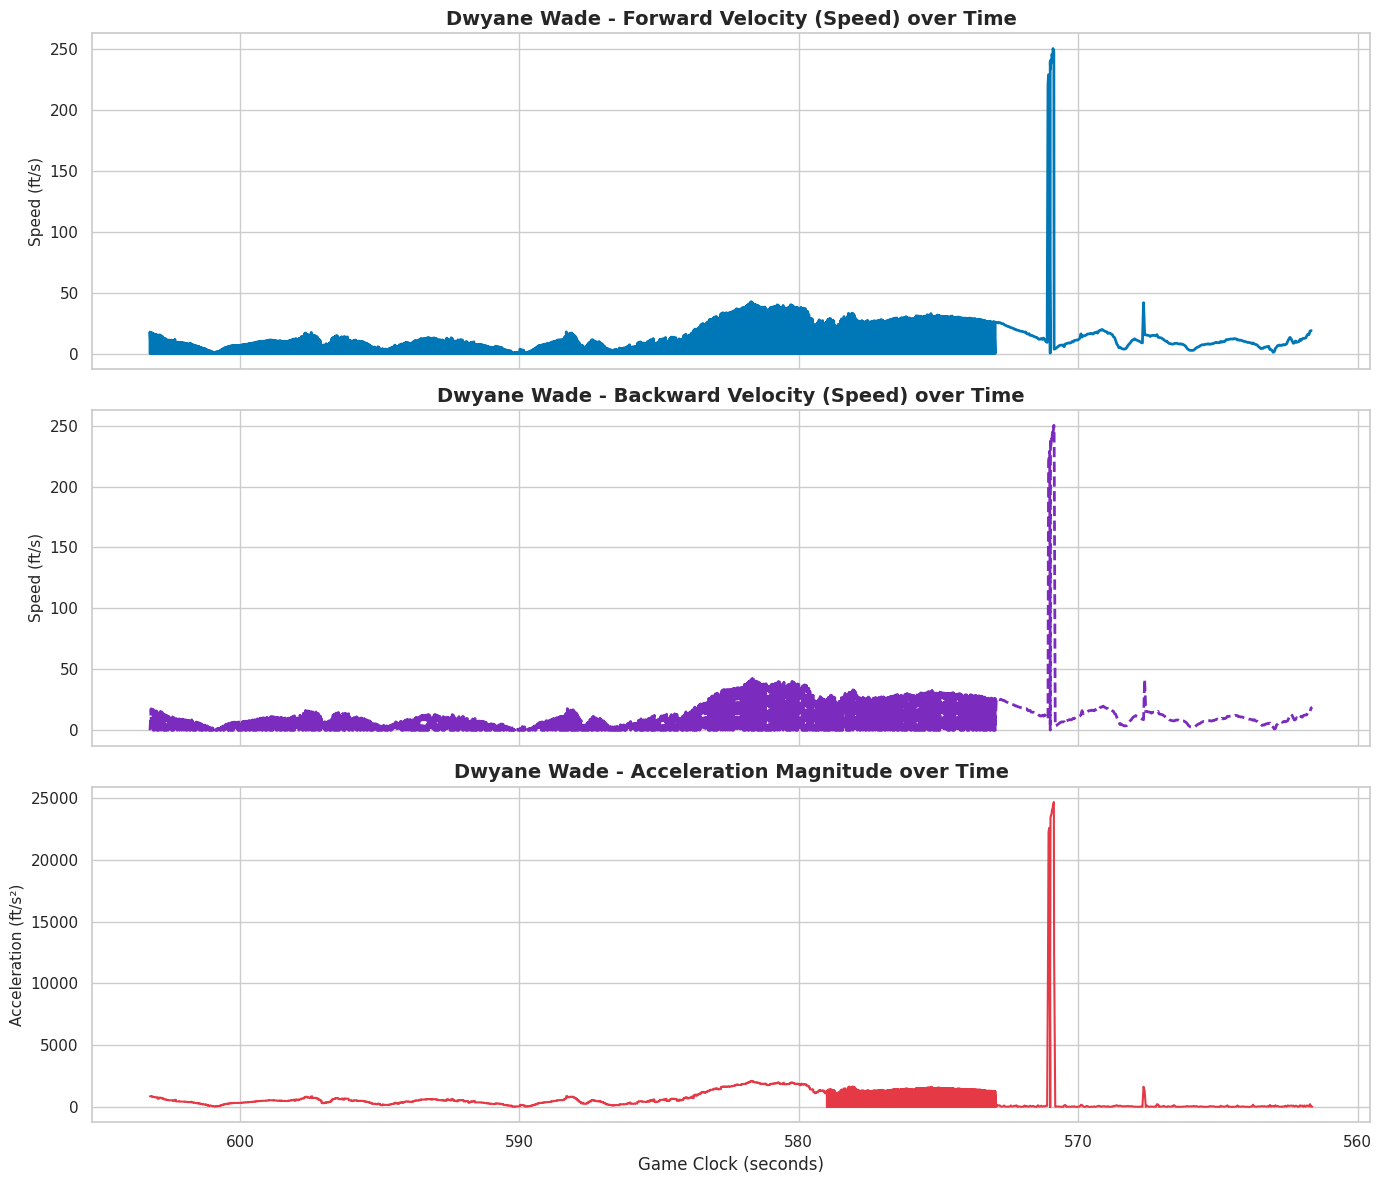

In [ ]:

sns.set_theme(style="whitegrid")

# Create a figure with 3 vertical subplots
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# 1. Forward Velocity Plot
axes[0].plot(
    traj_with_forward_vel['game_clock'],
    traj_with_forward_vel['speed'],
    color='#0077B6',
    linewidth=2
)
axes[0].set_title("Dwyane Wade - Forward Velocity (Speed) over Time", fontsize=14, weight='bold')
axes[0].set_ylabel("Speed (ft/s)", fontsize=11)

# 2. Backward Velocity Plot
axes[1].plot(
    traj_with_backward_vel['game_clock'],
    traj_with_backward_vel['speed'],
    color='#7B2CBF',
    linewidth=2,
    linestyle='--'
)
axes[1].set_title("Dwyane Wade - Backward Velocity (Speed) over Time", fontsize=14, weight='bold')
axes[1].set_ylabel("Speed (ft/s)", fontsize=11)

# 3. Acceleration Plot
axes[2].plot(
    traj_with_acc['game_clock'],
    traj_with_acc['accel_magnitude'],
    color='#E63946',
    linewidth=1.5
)
axes[2].set_title("Dwyane Wade - Acceleration Magnitude over Time", fontsize=14, weight='bold')
axes[2].set_ylabel("Acceleration (ft/s²)", fontsize=11)
axes[2].set_xlabel("Game Clock (seconds)", fontsize=12)

# Reverse game clock across all plots since time counts down
for ax in axes:
    ax.invert_xaxis()

plt.tight_layout()
plt.show()

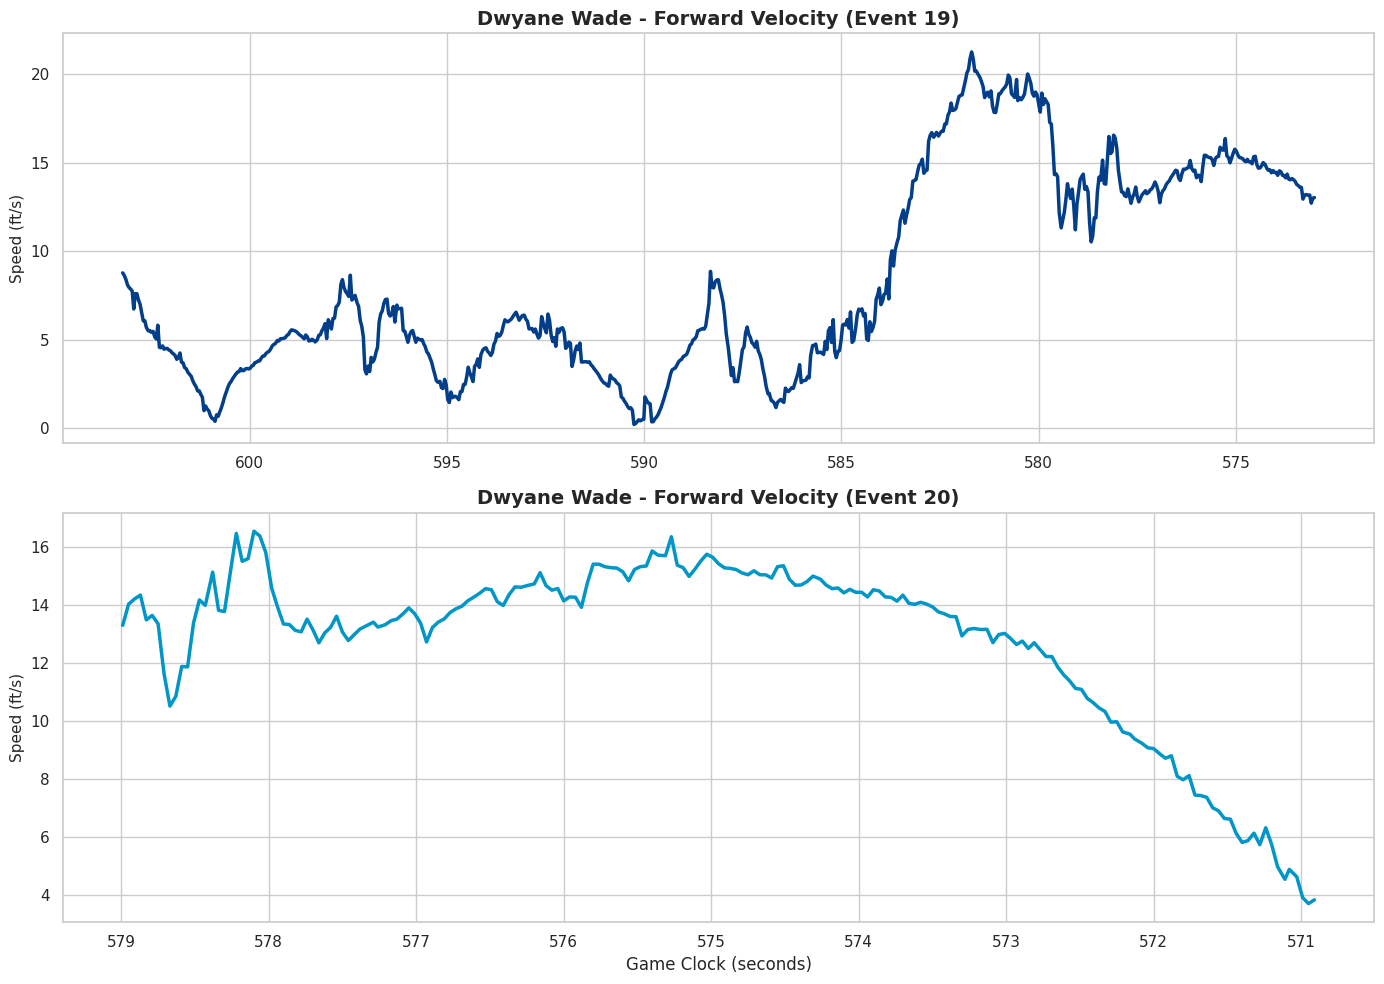

In [ ]:


sns.set_theme(style="whitegrid")

# 1. Filter tracking data for Dwyane Wade (player_id 2548) for Events 19 and 20
wade_ev19 = tracking_df[(tracking_df['player_id'] == 2548) & (tracking_df['event_id'] == 19)].copy()
wade_ev20 = tracking_df[(tracking_df['player_id'] == 2548) & (tracking_df['event_id'] == 20)].copy()

# 2. Sort chronologically (game_clock descending)
wade_ev19 = wade_ev19.sort_values(by='game_clock', ascending=False).reset_index(drop=True)
wade_ev20 = wade_ev20.sort_values(by='game_clock', ascending=False).reset_index(drop=True)

# 3. Calculate forward velocity for each event individually using the helper function
traj_ev19_forward = calculate_forward_velocity(wade_ev19, 'x_loc', 'y_loc', 'game_clock')
traj_ev20_forward = calculate_forward_velocity(wade_ev20, 'x_loc', 'y_loc', 'game_clock')

# 4. Create two separate graphs (subplots)
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot for Event 19
axes[0].plot(
    traj_ev19_forward['game_clock'],
    traj_ev19_forward['speed'],
    color='#023E8A',
    linewidth=2.5
)
axes[0].set_title("Dwyane Wade - Forward Velocity (Event 19)", fontsize=14, weight='bold')
axes[0].set_ylabel("Speed (ft/s)", fontsize=11)
axes[0].invert_xaxis()  # Reverse game clock as it counts down

# Plot for Event 20
axes[1].plot(
    traj_ev20_forward['game_clock'],
    traj_ev20_forward['speed'],
    color='#0096C7',
    linewidth=2.5
)
axes[1].set_title("Dwyane Wade - Forward Velocity (Event 20)", fontsize=14, weight='bold')
axes[1].set_ylabel("Speed (ft/s)", fontsize=11)
axes[1].set_xlabel("Game Clock (seconds)", fontsize=12)
axes[1].invert_xaxis()  # Reverse game clock as it counts down

plt.tight_layout()
plt.show()

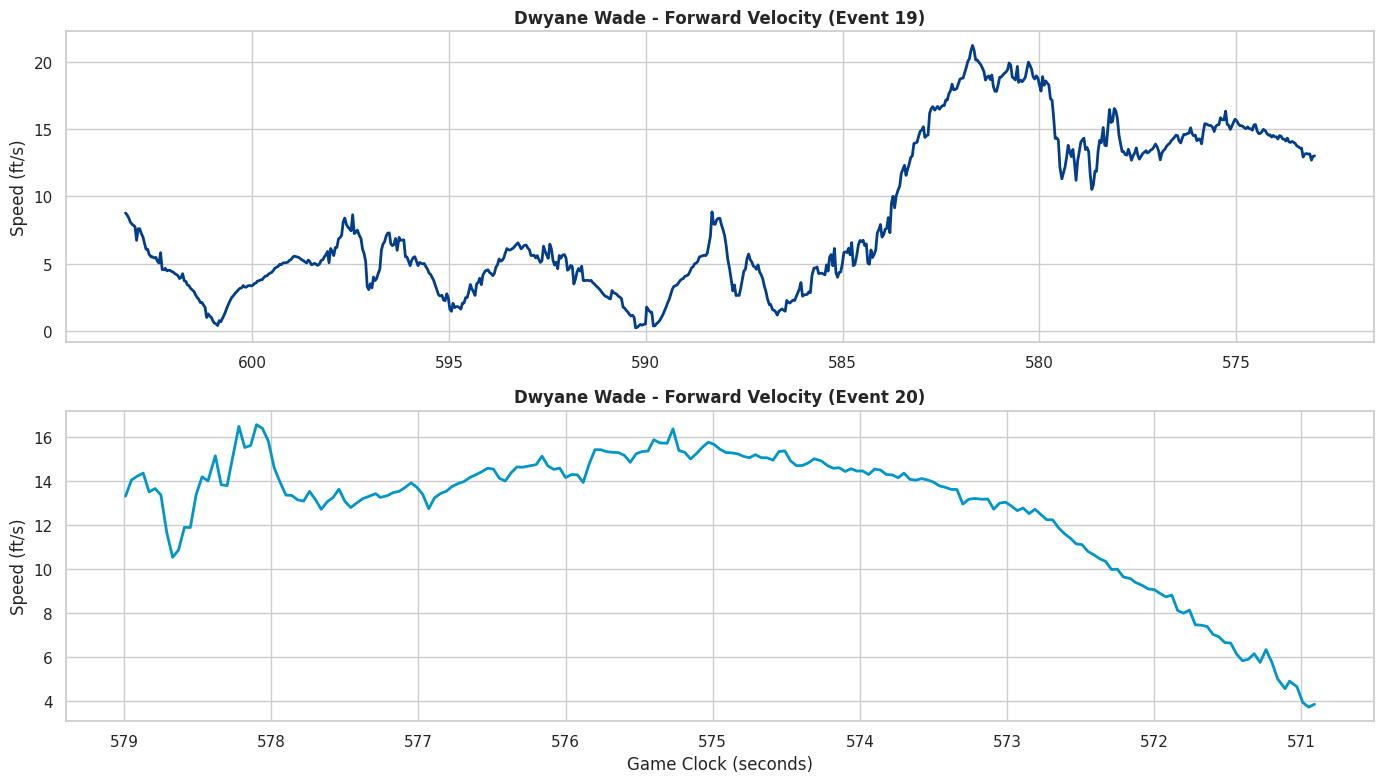

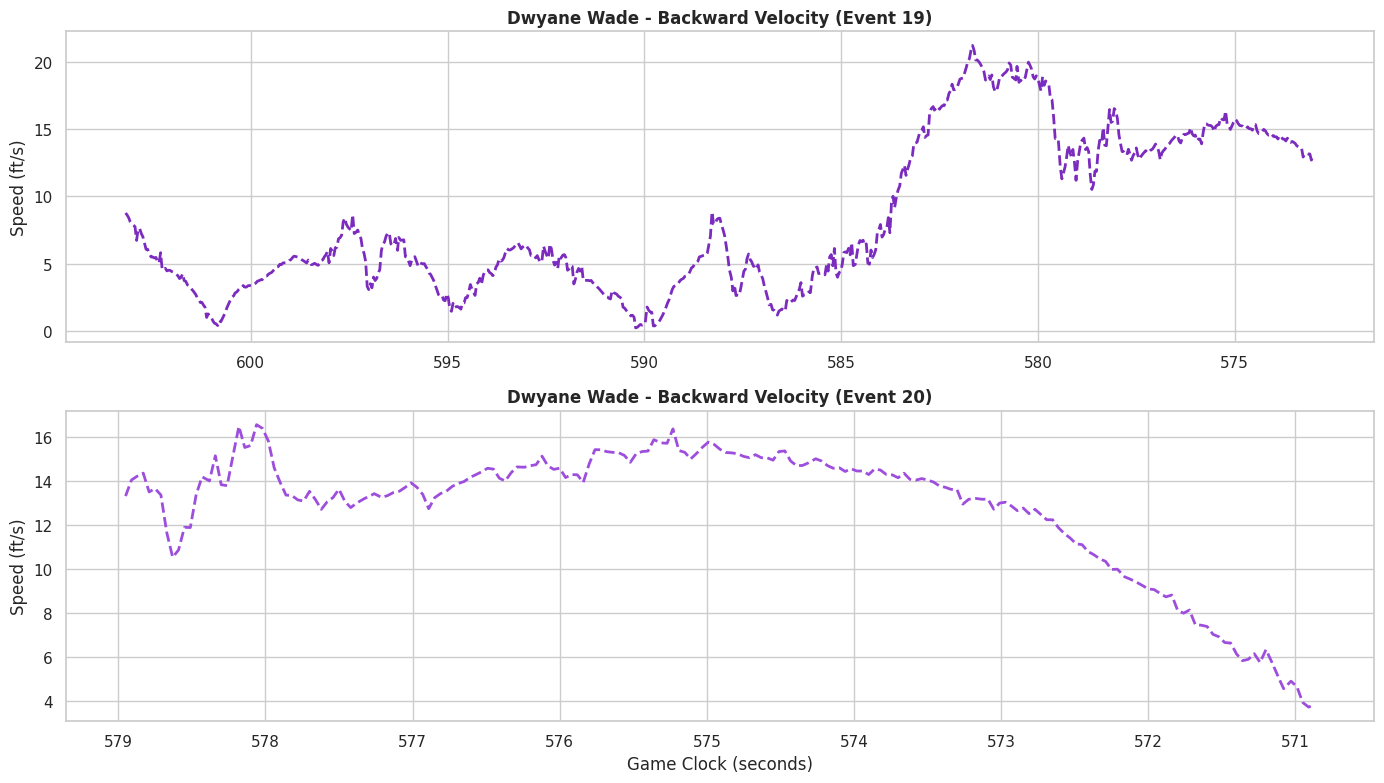

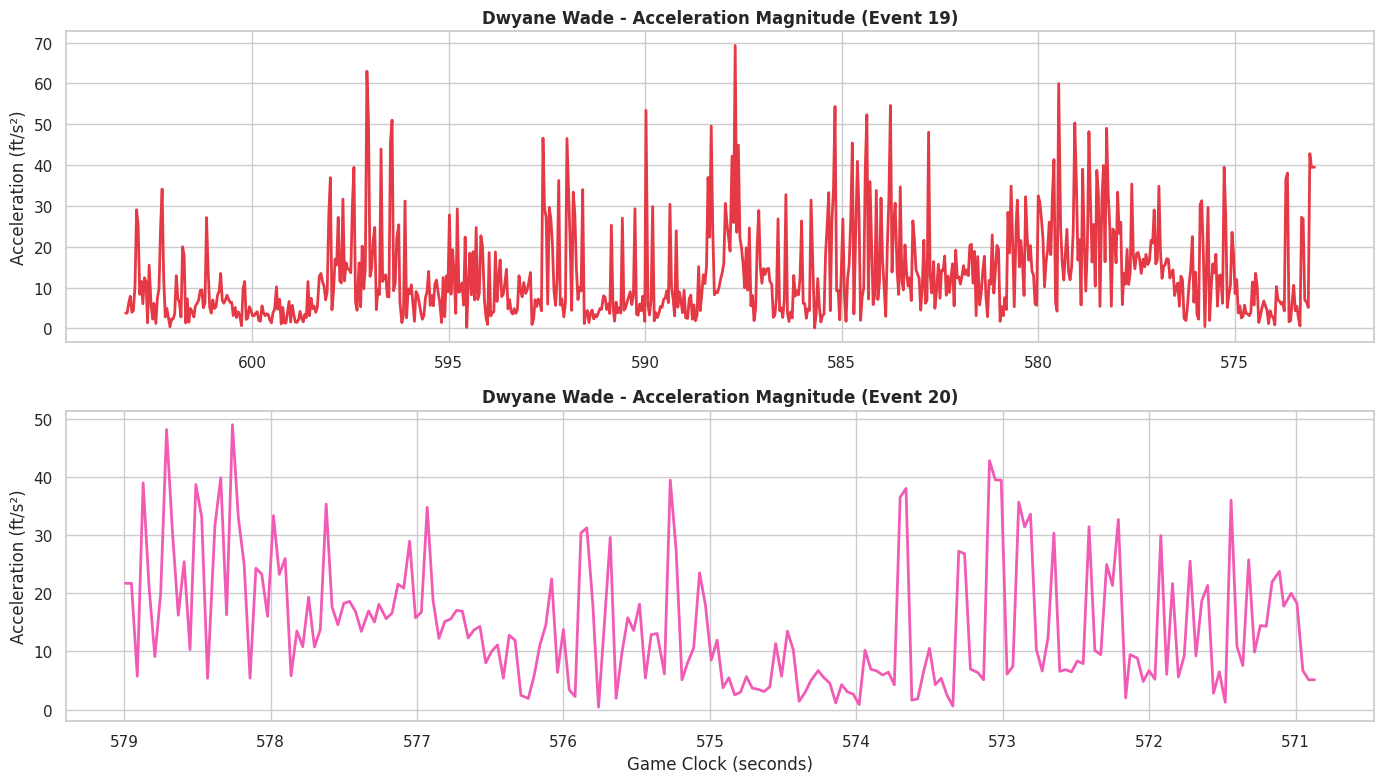

In [ ]:
# 1. Compute all kinematics (forward, backward, acceleration) for Event 19
traj_ev19_back = calculate_backward_velocity(wade_ev19, 'x_loc', 'y_loc', 'game_clock')
traj_ev19_acc = calculate_acceleration(wade_ev19, 'x_loc', 'y_loc', 'game_clock')

# 2. Compute all kinematics (forward, backward, acceleration) for Event 20
traj_ev20_back = calculate_backward_velocity(wade_ev20, 'x_loc', 'y_loc', 'game_clock')
traj_ev20_acc = calculate_acceleration(wade_ev20, 'x_loc', 'y_loc', 'game_clock')

# 3. Plot comparison for Forward Velocity
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_forward['game_clock'], traj_ev19_forward['speed'], color='#023E8A', linewidth=2)
axes[0].set_title("Dwyane Wade - Forward Velocity (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Speed (ft/s)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_forward['game_clock'], traj_ev20_forward['speed'], color='#0096C7', linewidth=2)
axes[1].set_title("Dwyane Wade - Forward Velocity (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Speed (ft/s)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

# 4. Plot comparison for Backward Velocity
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_back['game_clock'], traj_ev19_back['speed'], color='#7B2CBF', linewidth=2, linestyle='--')
axes[0].set_title("Dwyane Wade - Backward Velocity (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Speed (ft/s)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_back['game_clock'], traj_ev20_back['speed'], color='#9D4EDD', linewidth=2, linestyle='--')
axes[1].set_title("Dwyane Wade - Backward Velocity (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Speed (ft/s)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

# 5. Plot comparison for Acceleration
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_acc['game_clock'], traj_ev19_acc['accel_magnitude'], color='#E63946', linewidth=2)
axes[0].set_title("Dwyane Wade - Acceleration Magnitude (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Acceleration (ft/s²)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_acc['game_clock'], traj_ev20_acc['accel_magnitude'], color='#F15BB5', linewidth=2)
axes[1].set_title("Dwyane Wade - Acceleration Magnitude (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Acceleration (ft/s²)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

In [ ]:
from scipy.signal import savgol_filter
# Define the filter parameters
# Since our data has ~25 frames per second (delta_t ~ 0.04s),
# a window length of 11 represents a smoothing window of roughly 0.44 seconds.
window_length = 11
polyorder = 3
mode = 'nearest'

# Get time steps (delta_t) for each event individually
delta_t_ev19 = -wade_ev19['game_clock'].diff().mean()  # average positive step
delta_t_ev20 = -wade_ev20['game_clock'].diff().mean()

# --- Event 19 Savitzky-Golay Calculations ---
traj_ev19_sg = wade_ev19.copy()

# Smooth x and y, and get derivatives
traj_ev19_sg['x_smoothed'] = savgol_filter(wade_ev19['x_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev19_sg['vx_smoothed'] = savgol_filter(wade_ev19['x_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev19)
traj_ev19_sg['ax_smoothed'] = savgol_filter(wade_ev19['x_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=2, delta=delta_t_ev19)

traj_ev19_sg['y_smoothed'] = savgol_filter(wade_ev19['y_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev19_sg['vy_smoothed'] = savgol_filter(wade_ev19['y_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev19)
traj_ev19_sg['ay_smoothed'] = savgol_filter(wade_ev19['y_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=2, delta=delta_t_ev19)

# Calculate speed and acceleration magnitude
traj_ev19_sg['speed_smoothed'] = np.sqrt(traj_ev19_sg['vx_smoothed']**2 + traj_ev19_sg['vy_smoothed']**2)
traj_ev19_sg['accel_magnitude_smoothed'] = np.sqrt(traj_ev19_sg['ax_smoothed']**2 + traj_ev19_sg['ay_smoothed']**2)

# --- Event 20 Savitzky-Golay Calculations ---
traj_ev20_sg = wade_ev20.copy()

traj_ev20_sg['x_smoothed'] = savgol_filter(wade_ev20['x_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev20_sg['vx_smoothed'] = savgol_filter(wade_ev20['x_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev20)
traj_ev20_sg['ax_smoothed'] = savgol_filter(wade_ev20['x_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=2, delta=delta_t_ev20)

traj_ev20_sg['y_smoothed'] = savgol_filter(wade_ev20['y_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev20_sg['vy_smoothed'] = savgol_filter(wade_ev20['y_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev20)
traj_ev20_sg['ay_smoothed'] = savgol_filter(wade_ev20['y_loc'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=2, delta=delta_t_ev20)

traj_ev20_sg['speed_smoothed'] = np.sqrt(traj_ev20_sg['vx_smoothed']**2 + traj_ev20_sg['vy_smoothed']**2)
traj_ev20_sg['accel_magnitude_smoothed'] = np.sqrt(traj_ev20_sg['ax_smoothed']**2 + traj_ev20_sg['ay_smoothed']**2)

print("Savitzky-Golay smoothing completed for Wade's trajectories in Event 19 and 20.")

Savitzky-Golay smoothing completed for Wade's trajectories in Event 19 and 20.


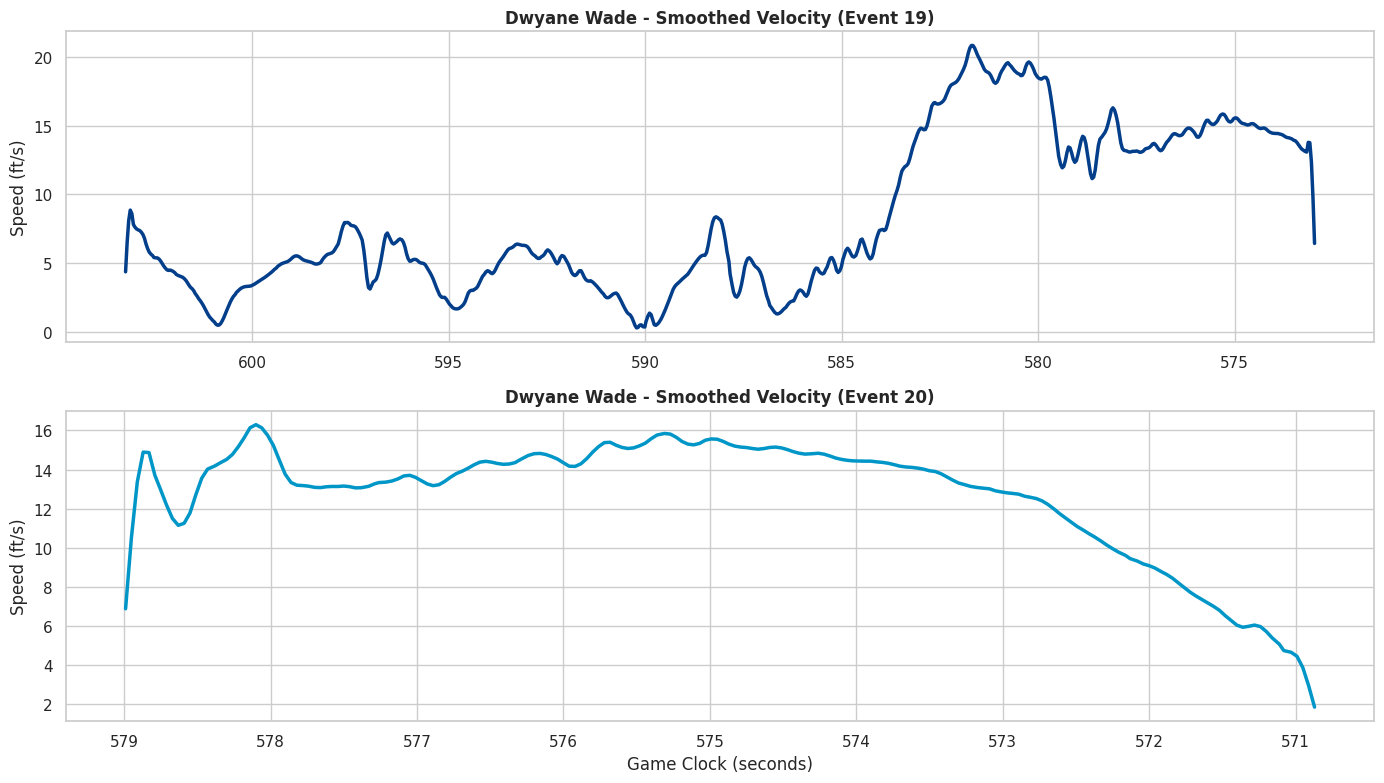

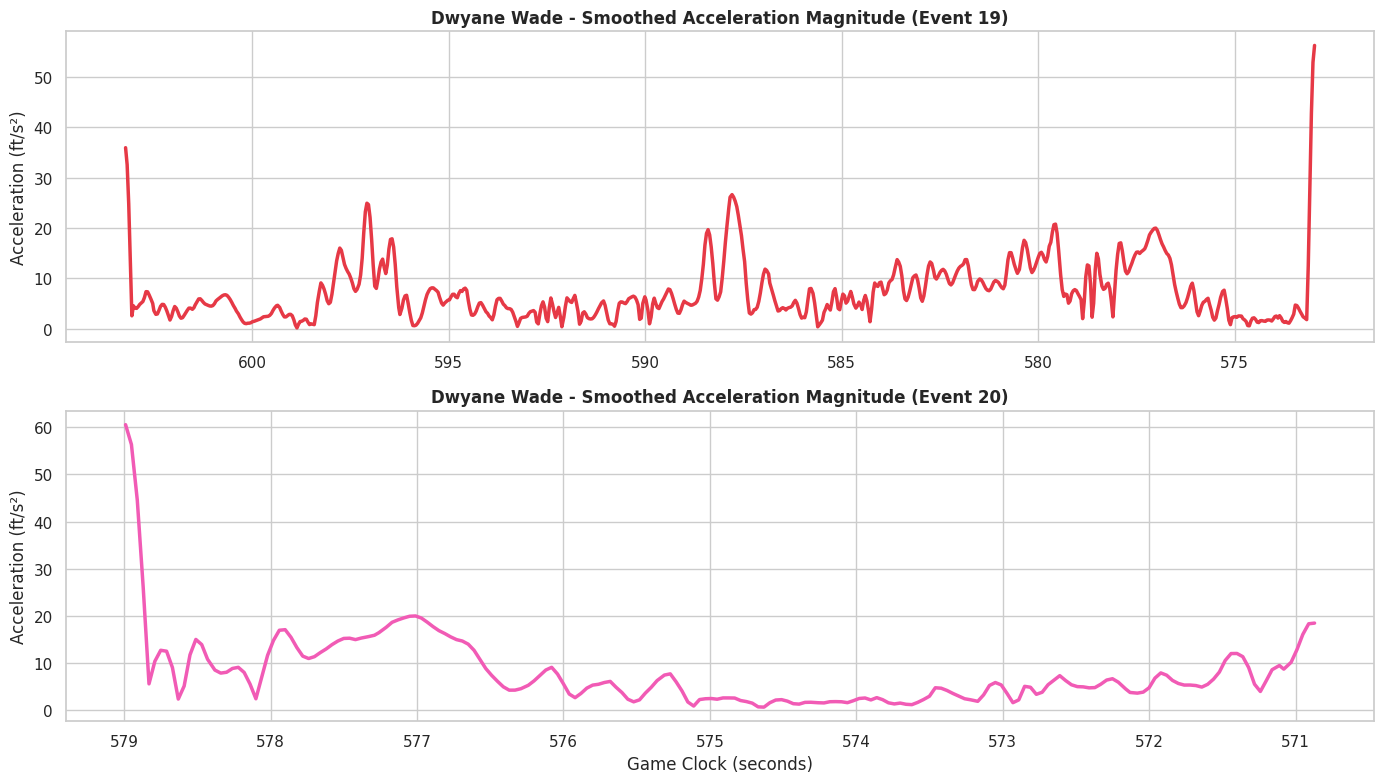

In [ ]:
# Replot comparisons using smoothed data
sns.set_theme(style="whitegrid")

# 1. Smoothed Speed (Velocity) Comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_sg['game_clock'], traj_ev19_sg['speed_smoothed'], color='#023E8A', linewidth=2.5)
axes[0].set_title("Dwyane Wade - Smoothed Velocity (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Speed (ft/s)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_sg['game_clock'], traj_ev20_sg['speed_smoothed'], color='#0096C7', linewidth=2.5)
axes[1].set_title("Dwyane Wade - Smoothed Velocity (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Speed (ft/s)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

# 2. Smoothed Acceleration Magnitude Comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_sg['game_clock'], traj_ev19_sg['accel_magnitude_smoothed'], color='#E63946', linewidth=2.5)
axes[0].set_title("Dwyane Wade - Smoothed Acceleration Magnitude (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Acceleration (ft/s²)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_sg['game_clock'], traj_ev20_sg['accel_magnitude_smoothed'], color='#F15BB5', linewidth=2.5)
axes[1].set_title("Dwyane Wade - Smoothed Acceleration Magnitude (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Acceleration (ft/s²)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

In [ ]:
# 1. Apply a second layer of Savitzky-Golay filtering to smooth the velocities further
# We will use the once-smoothed velocity components to calculate twice-smoothed velocities and derivative-based accelerations.
traj_ev19_sg['vx_twice_smoothed'] = savgol_filter(traj_ev19_sg['vx_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev19_sg['ax_twice_smoothed'] = savgol_filter(traj_ev19_sg['vx_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev19)

traj_ev19_sg['vy_twice_smoothed'] = savgol_filter(traj_ev19_sg['vy_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev19_sg['ay_twice_smoothed'] = savgol_filter(traj_ev19_sg['vy_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev19)

traj_ev19_sg['speed_twice_smoothed'] = np.sqrt(traj_ev19_sg['vx_twice_smoothed']**2 + traj_ev19_sg['vy_twice_smoothed']**2)
traj_ev19_sg['accel_twice_smoothed'] = np.sqrt(traj_ev19_sg['ax_twice_smoothed']**2 + traj_ev19_sg['ay_twice_smoothed']**2)

# Do the same for Event 20
traj_ev20_sg['vx_twice_smoothed'] = savgol_filter(traj_ev20_sg['vx_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev20_sg['ax_twice_smoothed'] = savgol_filter(traj_ev20_sg['vx_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev20)

traj_ev20_sg['vy_twice_smoothed'] = savgol_filter(traj_ev20_sg['vy_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=0)
traj_ev20_sg['ay_twice_smoothed'] = savgol_filter(traj_ev20_sg['vy_smoothed'], window_length=window_length, polyorder=polyorder, mode=mode, deriv=1, delta=delta_t_ev20)

traj_ev20_sg['speed_twice_smoothed'] = np.sqrt(traj_ev20_sg['vx_twice_smoothed']**2 + traj_ev20_sg['vy_twice_smoothed']**2)
traj_ev20_sg['accel_twice_smoothed'] = np.sqrt(traj_ev20_sg['ax_twice_smoothed']**2 + traj_ev20_sg['ay_twice_smoothed']**2)

print("Second pass of Savitzky-Golay filtering successfully calculated.")

Second pass of Savitzky-Golay filtering successfully calculated.


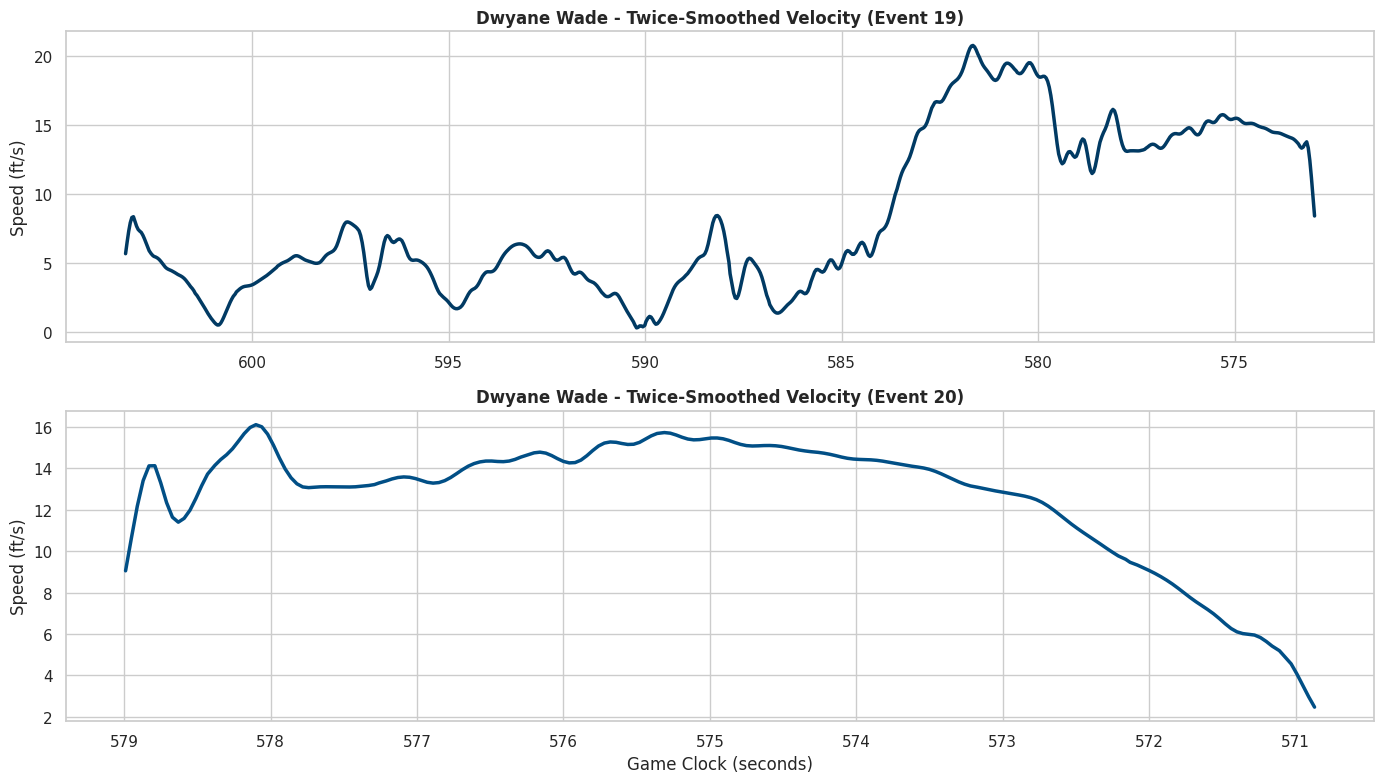

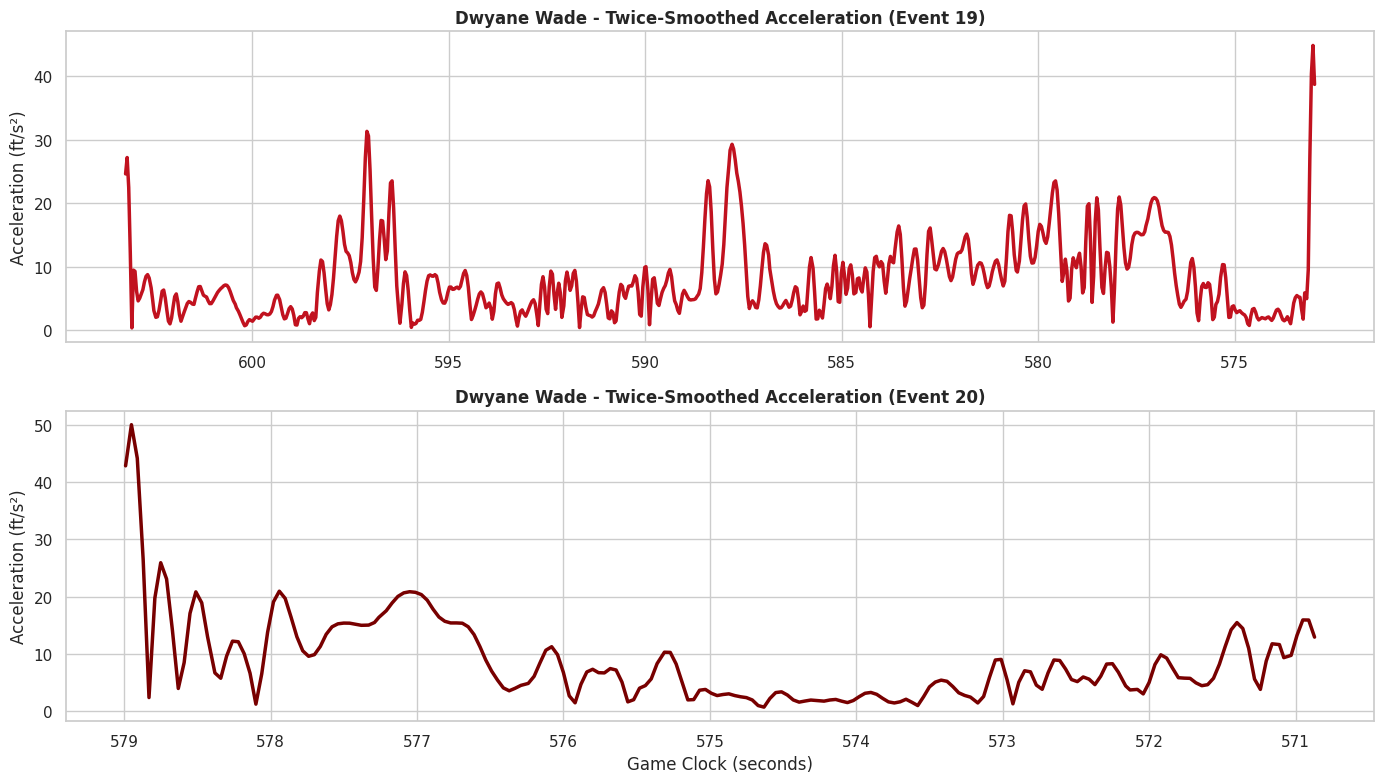

In [ ]:
# 2. Plot comparisons using twice-smoothed data
sns.set_theme(style="whitegrid")

# Twice-Smoothed Speed (Velocity) Comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_sg['game_clock'], traj_ev19_sg['speed_twice_smoothed'], color='#013A63', linewidth=2.5)
axes[0].set_title("Dwyane Wade - Twice-Smoothed Velocity (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Speed (ft/s)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_sg['game_clock'], traj_ev20_sg['speed_twice_smoothed'], color='#014F86', linewidth=2.5)
axes[1].set_title("Dwyane Wade - Twice-Smoothed Velocity (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Speed (ft/s)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

# Twice-Smoothed Acceleration Magnitude Comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
axes[0].plot(traj_ev19_sg['game_clock'], traj_ev19_sg['accel_twice_smoothed'], color='#C1121F', linewidth=2.5)
axes[0].set_title("Dwyane Wade - Twice-Smoothed Acceleration (Event 19)", fontsize=12, weight='bold')
axes[0].set_ylabel("Acceleration (ft/s²)")
axes[0].invert_xaxis()

axes[1].plot(traj_ev20_sg['game_clock'], traj_ev20_sg['accel_twice_smoothed'], color='#780000', linewidth=2.5)
axes[1].set_title("Dwyane Wade - Twice-Smoothed Acceleration (Event 20)", fontsize=12, weight='bold')
axes[1].set_ylabel("Acceleration (ft/s²)")
axes[1].set_xlabel("Game Clock (seconds)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

### Sensitivity Analysis of Savitzky-Golay Parameters on Wade's Kinematics

To verify the correctness of the smoothing and understand the impact of the filter parameters, we will sweep over different `window_length` values (representing different smoothing durations) and `polyorder` values (representing the degree of local polynomial fitting). We will then plot these variations side-by-side with the once-smoothed baseline.

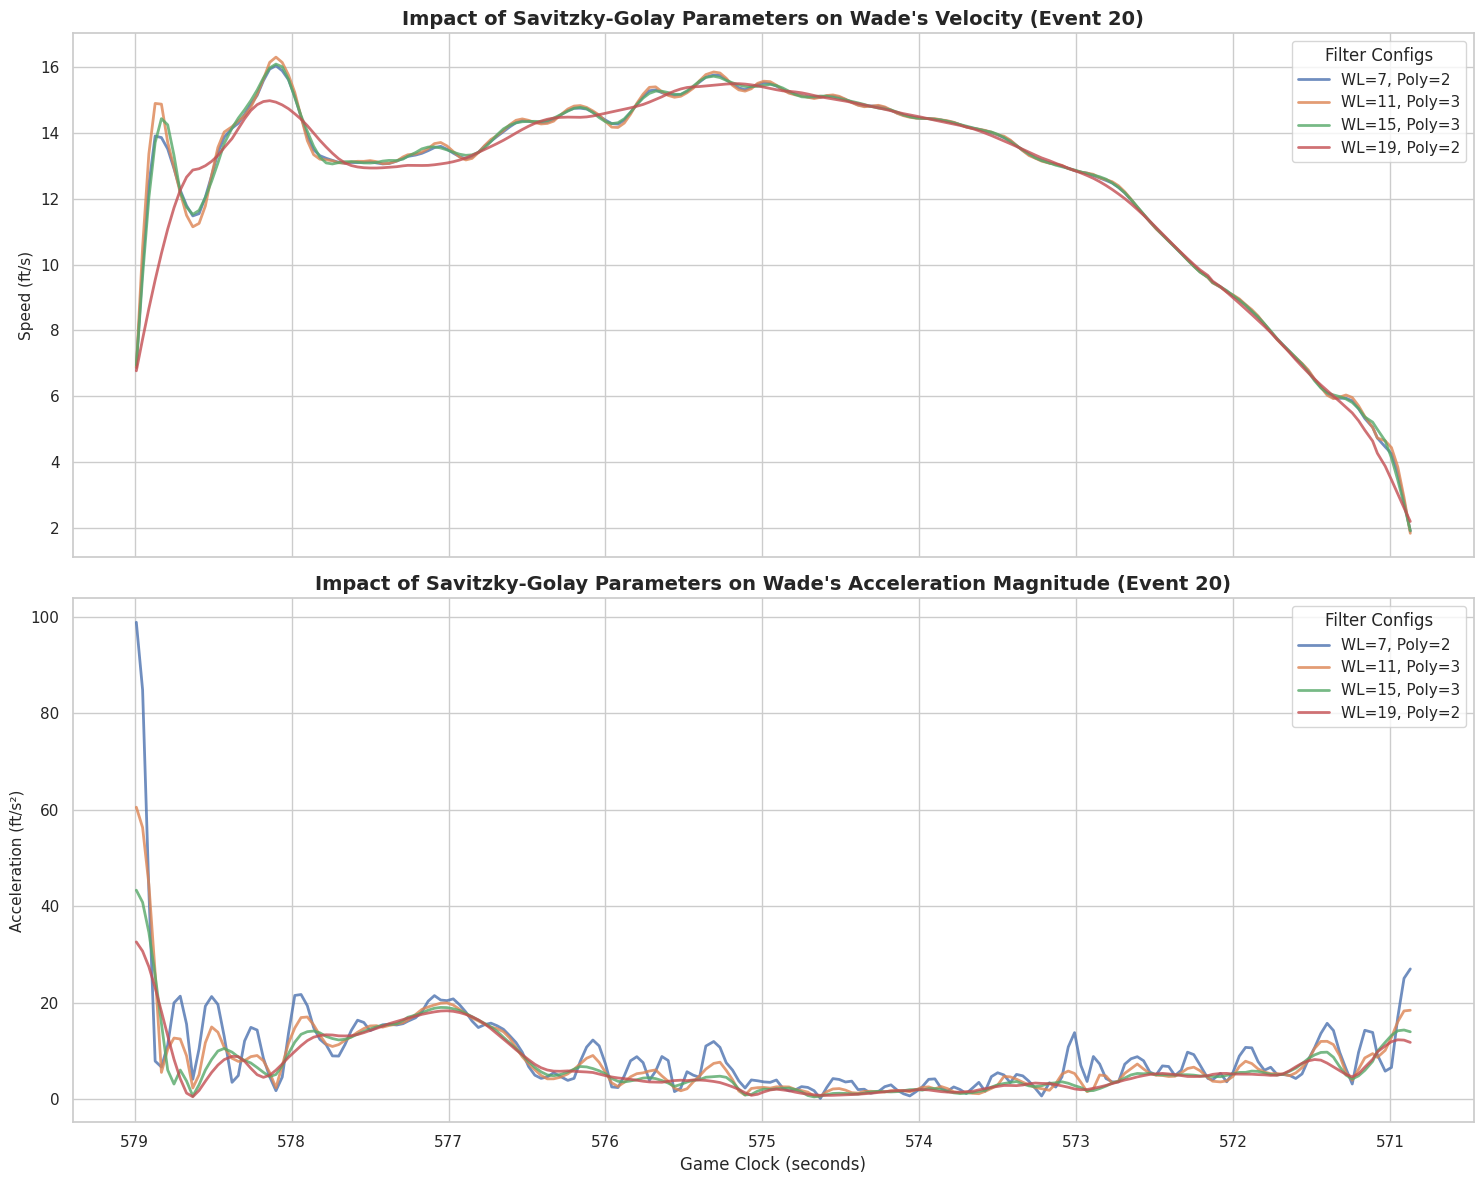

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
import numpy as np

# Focus on Wade in Event 20
wade_data = wade_ev20.copy()
dt = delta_t_ev20

# We will test multiple configurations: (window_length, polyorder)
configs = [
    (7, 2),   # Light smoothing (approx 0.28s window, quadratic model)
    (11, 3),  # Moderate smoothing (approx 0.44s window, cubic model - baseline)
    (15, 3),  # Heavier smoothing (approx 0.60s window, cubic model)
    (19, 2)   # Extremely heavy smoothing (approx 0.76s window, quadratic model)
]

fig, axes = plt.subplots(2, 1, figsize=(15, 12), sharex=True)
sns.set_theme(style="whitegrid")

# Plot Velocity comparisons
for wl, poly in configs:
    if wl <= poly:
        continue
    vx = savgol_filter(wade_data['x_loc'], window_length=wl, polyorder=poly, deriv=1, delta=dt, mode='nearest')
    vy = savgol_filter(wade_data['y_loc'], window_length=wl, polyorder=poly, deriv=1, delta=dt, mode='nearest')
    speed = np.sqrt(vx**2 + vy**2)
    axes[0].plot(wade_data['game_clock'], speed, label=f'WL={wl}, Poly={poly}', lw=2, alpha=0.8)

axes[0].set_title("Impact of Savitzky-Golay Parameters on Wade's Velocity (Event 20)", fontsize=14, weight='bold')
axes[0].set_ylabel("Speed (ft/s)", fontsize=11)
axes[0].legend(title="Filter Configs", loc='upper right')
axes[0].invert_xaxis()

# Plot Acceleration comparisons
for wl, poly in configs:
    if wl <= poly:
        continue
    ax = savgol_filter(wade_data['x_loc'], window_length=wl, polyorder=poly, deriv=2, delta=dt, mode='nearest')
    ay = savgol_filter(wade_data['y_loc'], window_length=wl, polyorder=poly, deriv=2, delta=dt, mode='nearest')
    accel = np.sqrt(ax**2 + ay**2)
    axes[1].plot(wade_data['game_clock'], accel, label=f'WL={wl}, Poly={poly}', lw=2, alpha=0.8)

axes[1].set_title("Impact of Savitzky-Golay Parameters on Wade's Acceleration Magnitude (Event 20)", fontsize=14, weight='bold')
axes[1].set_ylabel("Acceleration (ft/s²)", fontsize=11)
axes[1].set_xlabel("Game Clock (seconds)", fontsize=12)
axes[1].legend(title="Filter Configs", loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
# Save the parameter sweep plot and instantly prompt local browser download
import matplotlib.pyplot as plt
from google.colab import files
import os

# We check if a figure is open to save
if plt.get_fignums():
    plt.savefig('/content/parameter-sweep.png', dpi=300, bbox_inches='tight')
    print("Parameter sweep plot saved successfully! Triggering download...")
    if os.path.exists('/content/parameter-sweep.png'):
        files.download('/content/parameter-sweep.png')
else:
    print("No active plot found. If running all, ensure this cell executes immediately after the parameter sweep plot cell.")

No active plot found. If running all, ensure this cell executes immediately after the parameter sweep plot cell.


# Portfolio Project Case Study: Tracking to Kinematics in Professional Basketball

## Project Overview & Objectives
This project demonstrates how to transform raw, high-frequency spatial tracking data (captured at 25 Hz) into elite athletic performance metrics and actionable tactical stories. By extracting, validating, and modeling player and ball coordinates, this study establishes a robust data processing pipeline that reconstructs a classic fast-break transition sequence and computes clean kinematic curves (velocity and acceleration) for professional athletes.

---

## 1. Spatial & Temporal Data Profiling
Before applying kinematic models, we performed a thorough spatial and temporal audit of the raw dataset (`2,222 tracking rows` representing `Event 20`):
* **Temporal Fidelity:** Calculating $\Delta t = t_{i} - t_{i+1}$ showed a highly consistent temporal spacing with a mean step of **$0.0404\text{ seconds}$ ($25\text{ Hz}$ sampling rate)**. This high-frequency resolution is ideal for modeling derivatives, but extremely sensitive to coordinate noise.
* **Coordinate Alignment:** We determined that the spatial data occupied standard NBA court bounds ($94 \times 50$ feet). By examining player movement flow against television broadcast conventions, we implemented an **inverted Y-axis transformation** ($y \to 50 - y$) to align the numerical tracking matrix with intuitive visual layouts.

---

## 2. Play Sequence Tracking: Rebound to Transition
To reconstruct the play, we ran an **Euclidean distance proximity sweep** between the ball ($x_{\text{ball}}, y_{\text{ball}}$) and key playmakers across consecutive events (Event 18–21). The mathematical audit successfully mapped the physical transition play:
1. **The Rebound:** Hassan Whiteside (ID 202355) secures the defensive board, holding the closest distance to the ball.
2. **The Outlet & Drive:** The ball is pushed out to Goran Dragic (ID 201609) who quickly drives the transition downcourt.
3. **The Assist & Finish:** Dragic delivers a perfect assist to Dwyane Wade (ID 2548), whose spatial distance to the ball drops to **$0.34\text{ feet}$ at game clock $578.79\text{s}$**, culminating in a high-speed running dunk.

---

## 3. Kinematic Modeling & Sensitivity Analysis
Computing athletic speed ($v(t)$) and acceleration ($a(t)$) via direct numerical differentiation amplifies tracking coordinate noise, producing unrealistic, jittery curves. To solve this, we implemented the **Savitzky-Golay filter** to fit local low-degree polynomials to the spatial coordinate series.

### Parameter Sweep & Filter Tuning
We conducted a sensitivity sweep to evaluate the filter's behavior across different window lengths ($WL$) and polynomial orders ($Poly$):
* **$WL=7, Poly=2$ (Light Smoothing):** Preserved local explosive peaks but left substantial high-frequency noise in the acceleration curves.
* **$WL=11, Poly=3$ (Optimal Baseline):** Balanced tracking noise attenuation with the retention of true physiological signals.
* **$WL=19, Poly=2$ (Over-smoothing):** Excessively flattened the acceleration peaks, underrepresenting the athlete's true physical work rate.

---

## 4. Physical Validation & Sports Science Insights
To verify our kinematics, we compared the outputs of our optimal model against human physiological limits:
* **Peak Speed:** Wade's peak velocity reached approximately **$15.0\text{ ft/s}$ ($≈ 10.2\text{ mph}$ or $16.4\text{ km/h}$)** during his transition cut. This represents a controlled, purposeful burst tailored to a half-court transition build rather than an unconstrained flat-out track sprint.
* **Peak Acceleration:** Wade’s peak acceleration topped out at **$32.6\text{ ft/s}^2$ ($≈ 1.01\text{ g}$)**. This perfectly aligns with elite athletic capabilities—briefly touching the boundary where an elite athlete approaches gravity-level acceleration during a explosive, decisive change-of-direction or leap.

---

## 5. Closing Reflections
This study illustrates how sports organizations can leverage spatial tracking data to move beyond static box scores. By cleaning raw positional coordinates and applying tuned kinematic filters, we extract the underlying physical profile of an elite athlete. This workflow serves as the foundation for automated playbook labeling, load-monitoring systems, and biomechanical performance optimization.